# Pick models — β-VAE and supervised comparison

One pick line is the unit of analysis. Picks are scored individually, then
rolled up into 15-minute windows at 5-minute stride.

Four architectures on the identical feature matrix, split and cobot-task gate:
the β-VAE Chapter 3 specifies, two Isolation Forest variants, and a supervised
classifier. The gap between them is the reported contribution (D109, D111,
D128).

Pick grain rather than window grain: a CK or exception event labeled every
window it overlapped, which put most windows in the positive class and
collapsed the rare-event framing behind AUPRC.

| Outcome | What it means |
|---|---|
| `did_mismatch` | Robot executed a different quantity than it was told |
| `told_location_divergence` | System rerouted the cobot to a second slot after the item was reported missing at the first (§12) |
| `ck_shortfall` | Checker found fewer pieces than ordered (§11) |

`exc_short` is a strict subset of `did_mismatch` and is a validity check, never
a second outcome (D99, D124).

`told_location_divergence` is a recovery mechanism, not a picker deviation. When
a worker reports the item missing, the system directs the cobot to another slot
holding that item so the line does not become a CK. It is therefore an
intermediate state on the path to `ck_shortfall` rather than a failure in its
own right, and its negative class contains lines whose original slot was equally
wrong but had no alternative available. Any figure for this outcome must be read
with that in mind (§12).

Window labels use an exact binomial upper-tail test conditioned on window
size. Counting selects for busy windows; the proportional rule that replaced
it selected for near-empty ones — `-n_picks` alone scored AUROC 0.963. Base
rates come from training only, and windows under 30 picks are labeled NaN
rather than called normal.

Training is on known-normal picks only. A pick carrying any outcome is
excluded, and lines with no cobot task are excluded because their labels are
unobserved rather than negative (D104).

In [1]:
# One-time setup for a fresh machine — leave commented out otherwise. The
# first line pulls the CUDA build of torch so training runs on the GPU.
# %pip install torch --index-url https://download.pytorch.org/whl/cu128
# %pip install -q torch pandas numpy scikit-learn matplotlib pyarrow watermark\
# %pip install -U pyarrow
# %pip install shap

# Alternative: install everything listed in requirements.txt.
# import sys, subprocess
# r = subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"],
#                    capture_output=True, text=True)
# print(r.stdout[-2000:])

In [2]:
# Record which Python, torch and sklearn versions this run used, so I can tell
# later which machine produced the outputs. Falls back to printing versions by
# hand if the watermark extension is not installed.
try:
    %load_ext watermark
    %watermark -v -m -p pandas,numpy,torch,sklearn,matplotlib
except ModuleNotFoundError:
    import platform, sys
    import numpy, pandas
    print(f"Python   : {sys.version.split()[0]}")
    print(f"Platform : {platform.platform()}")
    for m in (pandas, numpy):
        print(f"{m.__name__:<10}: {m.__version__}")

Python implementation: CPython
Python version       : 3.12.10
IPython version      : 9.15.0

pandas    : 2.3.3
numpy     : 2.3.5
torch     : 2.13.0
sklearn   : 1.9.0
matplotlib: 3.10.0

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
CPU cores   : 16
Architecture: 64bit



In [3]:
# Imports, the fixed random seed (29), plot defaults, and two small helpers
# for watching slow cells.
from __future__ import annotations

import sys
import time
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Find the project folder. If I happen to open this notebook from inside
# wms_rpt/, PKG_DIR steps up one level so the package still imports.
_here = Path.cwd()
PKG_DIR = _here.parent if _here.name == "wms_rpt" else _here
sys.path.insert(0, str(PKG_DIR))

import wms_rpt as W
print("wms_rpt", W.__version__, "from", PKG_DIR)

RANDOM_STATE = 29          
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 120)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Jupyter buffers printed output, so every progress print below passes
# flush=True or I would see nothing until the cell finishes. `stage` wraps a
# slow step and prints when it starts and how long it took, so a stall tells
# me which phase it stalled in. `hms` turns seconds into h:mm:ss.

@contextmanager
def stage(name):
    """Bracket a slow cell so a stall names the phase it stalled in."""
    print(f"[{time.strftime('%H:%M:%S')}] {name} ...", flush=True)
    t = time.perf_counter()
    try:
        yield
    finally:
        print(f"[{time.strftime('%H:%M:%S')}] {name} done in "
              f"{time.perf_counter() - t:,.1f}s", flush=True)


def hms(sec):
    sec = int(sec)
    return f"{sec // 3600:d}:{sec % 3600 // 60:02d}:{sec % 60:02d}"

wms_rpt 1.6.0 from C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1


## 1. Inputs

In [4]:
# Load the clean parquet tables from notebook 1 and the cobot result tasks
# from notebook 3. `_pq` fails with a plain message naming the missing table
# instead of a cryptic file error.
_t0 = time.perf_counter()
print(f"[{time.strftime('%H:%M:%S')}] load parquet inputs ...", flush=True)

CLEAN_DIR = PKG_DIR / "data" / "clean"
RAW_DIR   = PKG_DIR / "data" / "raw"
OUT_DIR   = PKG_DIR / "reports"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def _pq(name):
    p = CLEAN_DIR / f"{name}.parquet"
    if not p.exists():
        raise FileNotFoundError(f"{p} — run wms_eda_cleaning.ipynb first")
    return pd.read_parquet(p)

picking   = _pq("picking")
bridge    = _pq("shippingintent_sku")
cks       = _pq("cks")
slot_hist = _pq("slot_history")
slots     = _pq("slots")
audits    = _pq("slot_audit_history")
tasks     = _pq("cobot_result_tasks")
workers   = _pq("workers")

# shippingintent_nbr is how I attach the CK rows that have no pickticket_id.
# picking already carries it; the fallback below re-reads it from the raw .rpt
# for older extracts that did not.
if "shippingintent_nbr" in picking.columns:
    intent_map = picking[["shippingintentline_id", "shippingintent_nbr"]]
    print(f"intent map: from picking, {len(intent_map):,} rows")
else:
    _map_pq = CLEAN_DIR / "picking_intent_map.parquet"
    if _map_pq.exists():
        intent_map = pd.read_parquet(_map_pq)
    else:
        _rpt = next(f for f in RAW_DIR.glob("*.rpt") if "icking" in f.name)
        intent_map, _ = W.read_rpt(
            _rpt, usecols=["shippingintentline_id", "shippingintent_nbr"])
        intent_map.to_parquet(_map_pq, index=False)
    print(f"intent map: re-read, {len(intent_map):,} rows")

print(f"[{time.strftime('%H:%M:%S')}] load parquet inputs done in "
      f"{time.perf_counter() - _t0:,.1f}s", flush=True)

[15:29:46] load parquet inputs ...
intent map: from picking, 733,787 rows
[15:29:51] load parquet inputs done in 5.1s


In [5]:
# Sanity check that I am running the right Python and the right copy of
# picks.py — Anaconda is a recurring wrong-launch trap. The sha1 tells me which
# version of the file is loaded; `loaded` confirms the dedupe helper is there.
import sys, hashlib, wms_rpt.picks as P
print("executable:", sys.executable)
print("picks.py  :", P.__file__)
print("sha1      :", hashlib.sha1(open(P.__file__, "rb").read()).hexdigest())
print("loaded    :", hasattr(P, "_dedupe_tasks"))

executable: C:\Users\barbarap\AppData\Local\Programs\Python\Python312\python.exe
picks.py  : C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1\wms_rpt\picks.py
sha1      : 244ca19d652b00238eae18f518cda217e5ae1adb
loaded    : True


In [6]:
# The hash crosswalks are retired (D100) — since the cleartext re-pull the IDs
# on both sides match directly. XW stays an empty dict: leaving the old maps in
# would pass the "is it empty" guard while matching nothing.
XW = {}

# No item crosswalk either. This used to be an empty two-column decoy frame,
# built only because build_labels gated did_mismatch on `item_xw is not None`
# — so passing None silently dropped my primary outcome. wms_rpt 1.6.0 gates
# on result_tasks instead, so the argument is gone (D137).

## 2. Spine, state, context, labels

`build_spine` de-duplicates byte-identical pick lines and keeps genuine
multi-row lines — the same line picked from two slots minutes apart. It raises
on a merge collision, because a suffixed `_x`/`_y` column breaks every
downstream key lookup.

`slot_state` joins backward as-of on `slot_history` with a 60-second minimum
gap (D124), and computes `hrs_since_slot_event` from a separate join that
excludes cobot pick events (D125).

Labels come from CK attachment, the cobot's own record and cross-system
comparison against `picking`. All are held out of the feature matrix by
`feature_columns()` and any of them disqualifies a pick from known-normal.

In [7]:
# Build everything the models need: the pick spine (one row per pick line),
# slot state, labels, cobot features, rolling context, the slot-audit features
# from notebook 2, and item/slot physical attributes — then stitch them into
# one feature matrix and check nothing leaked.
_t0 = time.perf_counter()
print(f"[{time.strftime('%H:%M:%S')}] spine / state / labels / features ...", flush=True)

spine, rep = W.build_spine(picking, intent_map, bridge)
ck_attach, rep = W.attach_cks(spine, cks, rep)
state, rep = W.slot_state(spine, slot_hist, slots, audits, rep)

labels, rep = W.build_labels(spine, cks, ck_attach, tasks, rep=rep,
                             picking=picking, xw=XW)

cobot = W.cobot_line_features(spine, tasks, XW, workers)
context = W.rolling_context(spine)

# A line with no cobot task has no label at all — not a "no", just unknown —
# so it stays out of training (D104).
has_task = cobot["has_told_location"].astype(bool)
print(f"lines without a cobot task: {(~has_task).sum():,} "
      f"({(~has_task).mean():.2%}) - excluded from training")

# Slot-audit features from notebook 2 (D98). That file is sorted by time, not
# in spine order, so I join on the keys and reindex. Lining rows up by
# position would silently misalign every one of them.
psf = pd.read_parquet(CLEAN_DIR / "pick_slot_features.parquet")
_k = ["pickticket_id", "shippingintentline_id"]
_cols = ["days_since_last_audit", "picks_since_last_audit",
         "reserved_units_at_pick"]
assert not psf.duplicated(_k).any(), "psf keys are not unique"

slotstate = (spine[_k].merge(psf[_k + _cols], on=_k, how="left")
                      .set_index(spine.index))
slotstate["has_prior_audit"] = slotstate["days_since_last_audit"].notna().astype(int)
print("slot-state join coverage:",
      f"{slotstate['reserved_units_at_pick'].notna().mean():.1%}")

# Item and slot physical attributes (D107). sku has the two-letter category
# prefix; itemid is the bare digits (D97) — same chop as notebook 2.
sa_ = pd.read_parquet(CLEAN_DIR / "slot_attributes.parquet")
ia_ = pd.read_parquet(CLEAN_DIR / "item_attributes.parquet")

_sp = spine[["slotid", "sku"]].copy()
_sp["slotid"] = _sp["slotid"].astype(str).str.strip()
_s = _sp["sku"].astype(str).str.strip()
_sp["itemid"] = _s.where(~_s.str[:2].str.isalpha(), _s.str[2:])
_sp["_i"] = spine.index

attrs = (_sp.merge(sa_, on="slotid", how="left")
            .merge(ia_, on="itemid", how="left", suffixes=("_slot", "_item"))
            .set_index("_i").reindex(spine.index)
            .drop(columns=["slotid", "sku", "itemid"]))
attrs["fit_ratio"] = attrs["item_volume"] / attrs["volume"].replace(0, pd.NA)
attrs["unit"] = attrs["unit"].astype("category").cat.codes   # size letter -> integer code

# D163: slot_state already brings in four slots columns under new names
# (pickzonepk -> pickzone, volume -> slot_volume, skumaxcount -> slot_max,
# size -> slot_size), and slot_attributes brings the same columns under their
# original names. So each one was in the matrix twice, perfectly correlated,
# two of the three byte-identical. Perfect twins split the SHAP credit between
# them, so each ranked about half as high as it should — and all three sit in
# the warehouse-configuration group that H3 predicts will lead. I drop the
# originals here, AFTER fit_ratio, which needs attrs["volume"]. The
# slot_-prefixed names stay: they say which side of the join they came from,
# and pickzone is the code rather than its surrogate key.
_DUPES = ["volume", "pickzonepk", "skumaxcount"]
attrs = attrs.drop(columns=[c for c in _DUPES if c in attrs.columns])

print("attr coverage:", attrs.notna().mean().round(3).to_dict())

# Put the matrix together. feature_columns() strips out every label column —
# told_location_divergence rides in with the cobot features, so I copy it over
# to labels first.
features = pd.concat([state, context, cobot,
                      slotstate[_cols + ["has_prior_audit"]], attrs], axis=1)
for lc in W.LABEL_COLS:
    if lc in cobot.columns and lc not in labels.columns:
        labels[lc] = cobot[lc]
features = features[W.feature_columns(features)]

print(f"spine    {len(spine):,} picks")
print(f"features {features.shape[1]} columns")
leak = [c for c in features.columns if c in W.LABEL_COLS]
assert not leak, f"label leaked into features: {leak}"

# D163 guard: no two features may be perfect correlates (|r| > 0.999). A
# duplicated feature halves its own SHAP credit and understates whichever RQ3
# group it belongs to — and no per-feature check would ever show it.
_num = features.select_dtypes("number").astype("float64")
_cm = _num.corr().abs()
_dup = [(i, j) for a, i in enumerate(_cm.columns)
        for j in _cm.columns[a + 1:] if _cm.loc[i, j] > 0.999]
assert not _dup, f"perfectly correlated feature pairs: {_dup} — see D163"
display(pd.Series(rep.label_rates).rename("rate").to_frame().style
        .format("{:.2%}"))

print(f"[{time.strftime('%H:%M:%S')}] spine / state / labels / features done in "
      f"{time.perf_counter() - _t0:,.1f}s", flush=True)

[15:29:51] spine / state / labels / features ...
lines without a cobot task: 8,462 (1.28%) - excluded from training
slot-state join coverage: 98.9%
attr coverage: {'sizeid': 1.0, 'depth': 1.0, 'width_slot': 1.0, 'height_slot': 1.0, 'isspecialsize': 1.0, 'aisle': 1.0, 'unit': 1.0, 'row': 1.0, 'length': 1.0, 'height_item': 1.0, 'width_item': 1.0, 'weight': 0.999, 'forecastrank': 1.0, 'item_volume': 1.0, 'item_density': 0.999, 'fit_ratio': 1.0}
spine    660,688 picks
features 44 columns


,rate
ck_shortfall,0.13%
is_recovery_pick,1.92%
did_mismatch,4.52%
exc_short,4.50%
exc_totefull,0.02%


[15:30:45] spine / state / labels / features done in 53.9s


In [59]:
# Do shortages cluster by slot? D125's explanation for the leak assumes they
# do, and the inventory-availability story implies it, but I had never
# measured it. For slots with at least 5 picks: how per-slot shortage rates
# spread out around the base rate.
_g = (has_task & spine["tspicked"].notna()).to_numpy()   # eligible = has a cobot task AND a pick timestamp
_d = pd.DataFrame({"slot": spine["slotid"].astype(str),
                   "y": labels["did_mismatch"].to_numpy()})[_g]
per = _d.groupby("slot")["y"].agg(["size", "sum", "mean"])
per = per[per["size"] >= 5]
print(f"slots with >=5 picks: {len(per):,}")
print(f"base rate: {_d['y'].mean():.2%}\n")

print("share of slots by their own shortage rate:")
print(pd.cut(per["mean"], [-0.01, 0, 0.05, 0.10, 0.25, 0.50, 1.0]
             ).value_counts().sort_index().to_string())

# If shortages had nothing to do with the slot, the count per slot would be
# close to binomial. Variance well above that (overdispersion) IS the
# clustering.
import numpy as np
p = _d["y"].mean()
exp_var = (per["size"] * p * (1 - p)).mean()
obs_var = per["sum"].var()
print(f"\nobserved variance in shortages per slot: {obs_var:.2f}")
print(f"variance expected if independent:          {exp_var:.2f}")
print(f"ratio: {obs_var / exp_var:.1f}x")

# What share of all shortages sit in the worst 5% of slots, and on what share
# of the picks?
per = per.sort_values("sum", ascending=False)
top = int(len(per) * 0.05)
print(f"\ntop 5% of slots hold {per['sum'].head(top).sum() / per['sum'].sum():.1%} "
      f"of all shortages, on {per['size'].head(top).sum() / per['size'].sum():.1%} "
      f"of the picks")

slots with >=5 picks: 21,164
base rate: 3.92%

share of slots by their own shortage rate:
mean
(-0.01, 0.0]    13071
(0.0, 0.05]      2897
(0.05, 0.1]      2128
(0.1, 0.25]      2087
(0.25, 0.5]       681
(0.5, 1.0]        300

observed variance in shortages per slot: 10.75
variance expected if independent:          1.12
ratio: 9.6x

top 5% of slots hold 45.9% of all shortages, on 14.4% of the picks


In [61]:
# D125 gradient check on the two cobot timing features that survived. Kept
# permanently: two other cobot features were dropped on this evidence plus
# the D158 ablation, and I want those exclusions to stay checkable rather than
# just asserted. execdate is a COMPLETION time, so anything anchored on the
# current task can contain that pick's own duration. For each survivor:
# did_mismatch rate by decile of the feature, with lift against the base rate.
# Then: is the outcome rate different where the feature is null?
_dropped = {
    "cobot_secs_since_robot_prev_task":
        "D156: 6.5x monotone gradient, 1.08% shortest decile to 7.15%",
    "cobot_task_ordinal_in_ticket":
        "D158: leaks through its difference with ordinal_in_ticket, "
        "1.54% at agreement against 8.66% one lower",
}
for _c, _why in _dropped.items():
    assert _c not in features.columns, f"{_c} is back in the matrix — {_why}"

_new = [c for c in ("cobot_robot_tasks_prev_15min", "cobot_robot_changed")
        if c in features.columns]
assert _new, "no cobot timing features present; check picks.py loaded"

gate = (has_task & spine["tspicked"].notna()).to_numpy()
y_all = labels["did_mismatch"].to_numpy()[gate]
base = y_all.mean()
print(f"base rate, gated population: {base:.2%} ({gate.sum():,} rows)\n")

for c in _new:
    v = features[c].to_numpy()[gate]
    ok = ~pd.isna(v)
    nun = pd.Series(v[ok]).nunique()
    print(f"=== {c}  (nulls {(~ok).mean():.1%}, {nun:,} distinct)")
    if nun < 3:
        print(pd.crosstab(pd.Series(v[ok]), pd.Series(y_all[ok]),
                          normalize="index").round(4).to_string(), "\n")
        continue
    d = pd.qcut(pd.Series(v[ok]), 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"d": d, "y": y_all[ok], "v": v[ok]}).groupby("d")
    tab = g.agg(n=("y", "size"), rate=("y", "mean"),
                lo=("v", "min"), hi=("v", "max"))
    tab["lift"] = (tab["rate"] / base).round(2)
    tab["rate"] = (tab["rate"] * 100).round(2)
    print(tab.to_string())
    print(f"    max/min lift: {tab['lift'].max() / tab['lift'].min():.1f}x\n")

print("=== nullness against the outcome")
for c in _new:
    m = pd.isna(features[c].to_numpy()[gate])
    if m.any() and not m.all():
        print(f"    {c:<34} rate where null {y_all[m].mean():.2%} | "
              f"present {y_all[~m].mean():.2%}")

base rate, gated population: 3.92% (646,820 rows)

=== cobot_robot_tasks_prev_15min  (nulls 0.3%, 56 distinct)
        n  rate    lo    hi  lift
d                                
0   77849  4.45   0.0   3.0  1.13
1  100383  4.61   4.0   5.0  1.18
2   65290  4.44   6.0   6.0  1.13
3   67886  4.24   7.0   7.0  1.08
4   64628  3.87   8.0   8.0  0.99
5   57355  3.78   9.0   9.0  0.96
6   47181  3.64  10.0  10.0  0.93
7   36960  3.40  11.0  11.0  0.87
8   65035  3.21  12.0  14.0  0.82
9   62347  2.83  15.0  55.0  0.72
    max/min lift: 1.6x

=== cobot_robot_changed  (nulls 0.3%, 2 distinct)
col_0       0       1
row_0                
0.0    0.9607  0.0393
1.0    0.9434  0.0566 

=== nullness against the outcome
    cobot_robot_tasks_prev_15min       rate where null 0.79% | present 3.93%
    cobot_robot_changed                rate where null 0.79% | present 3.93%


In [10]:
# Quick look: how many ck_shortfall positives are there in total, and how did
# the CK attachment go (attached / total / ambiguous)?
print(labels["ck_shortfall"].sum(), len(labels))
print(rep.ck_attached, rep.ck_total, rep.ck_ambiguous)

861 660688
13549 13664 641


In [11]:
# Pick the two targets and show every label's count and rate, with its role
# (target, validity check, or excluded-from-training only). wms_divergence is
# gone from LABEL_COLS since 1.6.0 — it was identically zero once D100 retired
# its crosswalk, and having to filter it out by hand here was the tell (D138).
TARGETS = ["did_mismatch", "told_location_divergence"]
TARGETS = [t for t in TARGETS if t in labels.columns]

summary = pd.DataFrame({
    "positives": labels[[c for c in W.LABEL_COLS if c in labels]].sum(),
    "rate": labels[[c for c in W.LABEL_COLS if c in labels]].mean(),
})
summary["role"] = ["target" if c in TARGETS else
                   "check" if c == "exc_short" else "excluded-from-training"
                   for c in summary.index]
display(summary.style.format({"positives": "{:,.0f}", "rate": "{:.2%}"}))

zero = summary.index[summary["rate"] == 0].tolist()
if zero:
    print(f"\nWARNING: {zero} have rate 0.00% — usually an empty crosswalk "
          f"or a missing input, not an absence of events.")

# A label can exist but be too thin to evaluate on any one split, which an
# exact-zero check misses. 30 positives is the floor I use in §8 and §12, so
# warn below 150 in total.
_thin = {c_: int(summary.loc[c_, "positives"]) for c_ in summary.index
         if 0 < summary.loc[c_, "rate"] and summary.loc[c_, "positives"] < 150}
if _thin:
    print(f"\nWARNING: {_thin} carry too few positives to survive a 60/20/20 "
          f"split at the 30-positive floor — report them or drop them "
          f"explicitly, do not let them return an undefined metric.")

# A label can also be missing entirely rather than all-zero, and the TARGETS
# filter above would hide that silently.
missing = [c for c in W.LABEL_COLS if c not in labels.columns]
if missing:
    print(f"\nWARNING: {missing} were not constructed at all — check what got "
          f"passed to build_labels.")

,positives,rate,role
ck_shortfall,861,0.13%,excluded-from-training
is_recovery_pick,"12,670",1.92%,excluded-from-training
did_mismatch,"29,849",4.52%,target
exc_short,"29,754",4.50%,check
exc_totefull,105,0.02%,excluded-from-training
told_location_divergence,"31,272",4.73%,target


In [12]:
# D126 confirmed: every duplicated (ticket, task) in the robot results is
# exactly 2 rows with the same payload and a different eventtype. This cell
# works out which of the two to keep.
t = tasks.copy()
k = ["pickticket_id", "jobtaskid"]

print("eventtype values:")
print(t["eventtype"].value_counts(dropna=False).to_string())

print("\nper duplicate group, which eventtype pairs occur:")
pairs = (t[t.duplicated(k, keep=False)]
         .groupby(k, observed=True)["eventtype"]
         .apply(lambda s: " + ".join(sorted(s.astype(str)))))
print(pairs.value_counts().head(10).to_string())

# Does execdate differ by eventtype? If one event type carries the real
# completion time and the other a placeholder, only one is usable.
ed = pd.to_datetime(t["execdate"], errors="coerce")
print("\nexecdate null rate and range by eventtype:")
for ev, grp in t.assign(_ed=ed).groupby("eventtype", observed=True):
    print(f"  {str(ev):<28} nulls {grp['_ed'].isna().mean():>6.2%}  "
          f"{grp['_ed'].min()} -> {grp['_ed'].max()}")

# ts is when the row was exported; execdate is when the robot says it
# executed. If ts varies between the two emissions but execdate does not,
# execdate is the stable field to build on.
tsp = pd.to_datetime(t["ts"], errors="coerce")
d = t.assign(_ts=tsp, _ed=ed)[t.duplicated(k, keep=False)]
g = d.groupby(k, observed=True)
print(f"\ngroups where ts varies:       {(g['_ts'].nunique() > 1).mean():.2%}")
print(f"groups where execdate varies: {(g['_ed'].nunique() > 1).mean():.2%}")

# The 0.02% of groups where the payload really does differ need a rule, not
# silence — show a few.
bad = g[["execdate", "execrobot", "execqty"]].nunique(dropna=False)
bad = bad[(bad > 1).any(axis=1)]
print(f"\ngroups with a varying execution payload: {len(bad):,}")
if len(bad):
    print(d.set_index(k).loc[bad.index[:3]]
           [["eventtype", "execdate", "execrobot", "execqty", "exceptioncode"]]
           .to_string())

eventtype values:
eventtype
PICKCOMPLETE      614222
PICK              571909
CANCELCOMPLETE         0
CANCELREJECT           0
ACCEPT                 0
CANCEL                 0
NEW                    0
DUPTOTE                0
REJECT                 0
TOTEINDUCT             0
TOTEMOVE               0
UPDATE                 0
UPDATECOMPLETE         0
UPDATEREJECT           0

per duplicate group, which eventtype pairs occur:
eventtype
PICK + PICKCOMPLETE    571832

execdate null rate and range by eventtype:
  PICK                         nulls  0.32%  2025-12-01 05:06:23.733000-05:00 -> 2025-12-31 16:15:37.747000-05:00
  PICKCOMPLETE                 nulls  0.32%  2025-12-01 05:06:23.733000-05:00 -> 2025-12-31 16:15:37.747000-05:00

groups where ts varies:       93.82%
groups where execdate varies: 0.02%

groups with a varying execution payload: 99
                                                                                       eventtype                       execdate execrobot  e

## 3. Known-normal split

A pick carrying any outcome is out of training, not only one carrying the
outcome being modelled.

The split is 60/20/20 chronological, never random: picks are autocorrelated
through shift, wave and replenishment cycles. Test straddles the 12-23
`UnitMode` audit change (D90).

`did_mismatch` is not flat across the split — 4.03% on val against 3.01% on
test, so the rate falls through late December rather than rising. The earlier
6.25% was the pre-D134 figure: 6,736 lines with no pick timestamp carry a
66.4% rate and land entirely in test on a chronological sort, which put 3.24
points on it. D136 recorded that inflated figure as a finding and is retracted
(D147). Test precision is if anything penalised by the lower base rate there,
not helped.

In [13]:
# Chronological 60/20/20 split — never random, because picks are correlated
# through shifts, waves and replenishment cycles — and the known-normal set the
# β-VAE is fitted on.
order = spine["tspicked"].sort_values(kind="mergesort").index

# Lines with no pick timestamp are not picks (D134): 2,225 were never assigned
# to a picker and 4,511 were assigned but never recorded a picked quantity.
# They carry a 66.4% did_mismatch rate with almost entirely imputed features —
# a model would separate them by absence, not by anything it learned.
# sort_values puts NaT last, so they would all land in test and push the test
# rate to 6.25% against 3.01%. That 3.24-point inflation is what D147
# retracts. Dropped here.
_has_ts = spine["tspicked"].notna()
print(f"dropping {int((~_has_ts).sum()):,} lines with no pick timestamp "
      f"({(~_has_ts).mean():.2%})")
order = order[_has_ts.loc[order].to_numpy()]

n = len(order)
i_tr, i_va = int(0.6 * n), int(0.8 * n)
idx_train, idx_val, idx_test = order[:i_tr], order[i_tr:i_va], order[i_va:]

normal = W.known_normal(labels) & has_task
fit_idx = idx_train[normal.loc[idx_train].to_numpy()]

for nm, ix in [("train", idx_train), ("val", idx_val), ("test", idx_test)]:
    t = spine.loc[ix, "tspicked"]
    print(f"{nm:<6} {len(ix):>8,}  {t.min():%Y-%m-%d %H:%M} -> {t.max():%Y-%m-%d %H:%M}")
print(f"\nknown-normal overall  {normal.mean():.1%}")
print(f"fitted on            {len(fit_idx):,} known-normal training picks")
for c in TARGETS:
    print(f"  {c:<26} val {labels.loc[idx_val, c].mean():.2%} "
          f"| test {labels.loc[idx_test, c].mean():.2%}")

dropping 6,736 lines with no pick timestamp (1.02%)
train   392,371  2025-12-01 05:06 -> 2025-12-16 10:51
val     130,790  2025-12-16 10:51 -> 2025-12-21 16:28
test    130,791  2025-12-21 16:28 -> 2025-12-31 16:36

known-normal overall  92.0%
fitted on            363,646 known-normal training picks
  did_mismatch               val 4.03% | test 3.01%
  told_location_divergence   val 4.53% | test 3.34%


In [60]:
# What actually disqualifies a pick from known-normal, and how much each
# condition contributes. §3.8.2 lists six conditions; one that fires on
# nothing should be named as such rather than implied to be active. Prints
# each label's count and rate on the gated population, then the known-normal
# share.
_g = (has_task & spine["tspicked"].notna()).to_numpy()
print(f"eligible picks: {_g.sum():,}\n")
for c in W.LABEL_COLS:
    if c in labels.columns:
        v = labels[c].fillna(0).astype(bool).to_numpy()[_g]
        print(f"  {c:<26} fires on {v.sum():>7,} ({v.mean():>6.2%})")
    else:
        print(f"  {c:<26} NOT PRESENT in labels")

_kn = W.known_normal(labels).to_numpy()[_g]
print(f"\nknown-normal: {_kn.mean():.1%} ({_kn.sum():,} picks)")

eligible picks: 646,820

  ck_shortfall               fires on     800 ( 0.12%)
  is_recovery_pick           fires on   7,256 ( 1.12%)
  did_mismatch               fires on  25,375 ( 3.92%)
  exc_short                  fires on  25,280 ( 3.91%)
  exc_totefull               fires on     102 ( 0.02%)
  told_location_divergence   fires on  30,022 ( 4.64%)

known-normal: 93.9% (607,049 picks)


## 4. Preprocessing

Fitted on known-normal training picks only, then applied unchanged to val and
test. Median imputation with a missingness indicator for the sparse blocks.

This is the β-VAE's requirement. The supervised model in §7 handles NaN
natively and does not go through it.

In [15]:
# Second, independent measurement of the no-pick-timestamp groups. My first
# pass tested "any non-null column in ck_attach", which is a probe artifact and
# not D134's definition — the 160 figure needs confirming on its own terms.
_no_ts = spine["tspicked"].isna()
print(f"no pick timestamp: {int(_no_ts.sum()):,}\n")

print("ck_attach shape:", ck_attach.shape,
      "| index matches spine:", ck_attach.index.equals(spine.index))
print("ck_attach non-null by column:")
print(ck_attach.notna().mean().round(4).to_string())

# Check side: look the spine keys up directly in the raw CK table instead.
_k = ["pickticket_id", "shippingintentline_id"]
if all(c in cks.columns for c in _k):
    _in_cks = spine[_k].apply(tuple, axis=1).isin(
        set(cks[_k].apply(tuple, axis=1)))
    print(f"\nno ts AND present in cks: {int((_no_ts & _in_cks).sum()):,}")
else:
    print("\ncks lacks the spine keys; columns:", list(cks.columns)[:20])

# Assignment side: no picker vs picker assigned, and whatever is left over.
_no_picker = spine["picker_employee_id"].isna()
print(f"\nno ts, no picker assigned: {int((_no_ts & _no_picker).sum()):,}")
print(f"no ts, picker assigned:    {int((_no_ts & ~_no_picker).sum()):,}")

# D134 says neither group recorded a picked quantity. Test that directly on
# every quantity column.
_qty = [c for c in spine.columns if "quantitypicked" in c.lower()]
for c in _qty:
    print(f"{c}: null on no-ts {spine.loc[_no_ts, c].isna().mean():.1%} "
          f"| zero on no-ts {(spine.loc[_no_ts, c] == 0).mean():.1%}")

# Exact counterfactual: what the test rate would be if these lines had NOT
# been dropped, on this same spine — so the "points off test" figure is
# measured here rather than inherited from the pre-D133 run.
_order_all = spine["tspicked"].sort_values(kind="mergesort").index
_test_all = _order_all[int(0.8 * len(_order_all)):]
_r_all = labels.loc[_test_all, "did_mismatch"].mean()
_r_now = labels.loc[idx_test, "did_mismatch"].mean()
print(f"\ntest did_mismatch with no-ts lines kept: {_r_all:.2%} "
      f"({len(_test_all):,} rows)")
print(f"test did_mismatch as split:             {_r_now:.2%} "
      f"({len(idx_test):,} rows)")
print(f"points removed by the D134 drop:        {(_r_all - _r_now) * 100:.2f}")

no pick timestamp: 6,736

ck_attach shape: (13549, 3) | index matches spine: False
ck_attach non-null by column:
_ckrow      1.0000
_pickrow    1.0000
gap         0.6743

cks lacks the spine keys; columns: ['ck_id', 'shippingintent_nbr', 'ck_ts', 'cker_employee_id', 'tsstarted', 'sku', 'ck_quantity', 'slotid', 'quantityfoundbyck', 'iswrongitem', 'pickticket_id', 'tspicked', 'picker_employee_id', 'slotlocation', 'pick_quantity', 'quantitypicked', 'ck_shortfall_qty', 'ck_found_none', 'ck_fill_rate']

no ts, no picker assigned: 2,225
no ts, picker assigned:    4,511
quantitypicked: null on no-ts 100.0% | zero on no-ts <NA>

test did_mismatch with no-ts lines kept: 6.25% (132,138 rows)
test did_mismatch as split:             3.01% (130,791 rows)
points removed by the D134 drop:        3.24


In [16]:
# Fit the preprocessor on the known-normal TRAINING picks only, then apply it
# unchanged to train, val and test. Numeric columns: fill blanks with the
# median and add a "was missing" flag, then standardise. Categorical columns:
# fill with the most common value, then one-hot. Output goes to float32 for
# torch.
_t0 = time.perf_counter()
print(f"[{time.strftime('%H:%M:%S')}] preprocessing fit+transform ...", flush=True)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import os

os.environ["LOKY_MAX_CPU_COUNT"] = "16"

num_cols = [c for c in features.columns
            if pd.api.types.is_numeric_dtype(features[c])]
cat_cols = [c for c in features.columns if c not in num_cols]
print(f"{len(num_cols)} numeric, {len(cat_cols)} categorical: {cat_cols}")

try:
    _ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                         min_frequency=0.01)
except TypeError:   # older scikit-learn spells it sparse= instead of sparse_output=
    _ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", _ohe)]), cat_cols),
], remainder="drop")

X_fit = pre.fit_transform(features.loc[fit_idx])
X_tr = pre.transform(features.loc[idx_train])
X_va = pre.transform(features.loc[idx_val])
X_te = pre.transform(features.loc[idx_test])
X_fit, X_tr, X_va, X_te = (np.asarray(a, dtype="float32")
                           for a in (X_fit, X_tr, X_va, X_te))
print(f"design matrix: {X_fit.shape[1]} columns | fit {X_fit.shape[0]:,}")

print(f"[{time.strftime('%H:%M:%S')}] preprocessing fit+transform done in "
      f"{time.perf_counter() - _t0:,.1f}s", flush=True)

[15:32:15] preprocessing fit+transform ...
43 numeric, 1 categorical: ['slot_size']
design matrix: 65 columns | fit 363,646
[15:32:23] preprocessing fit+transform done in 8.0s


In [17]:
# Alignment guard. The design matrices carry no index, so every score-to-label
# pairing downstream is by position and nothing would catch a mismatch. Assert
# the row counts agree and print the date range of each split.
for nm, ix, X in [("train", idx_train, X_tr), ("val", idx_val, X_va),
                  ("test", idx_test, X_te)]:
    assert len(X) == len(ix), (nm, len(X), len(ix))
    t = spine.loc[ix, "tspicked"]
    print(f"{nm:6s} rows {len(X):>8,}  gated {int(has_task.loc[ix].sum()):>8,}  "
          f"{t.min():%Y-%m-%d %H:%M} -> {t.max():%Y-%m-%d %H:%M}")

# Reusable gates: true/false masks for "has a cobot task", one per split.
# Apply one to a score array before pairing it with a gated label.
tr_gate = has_task.loc[idx_train].to_numpy()
va_gate = has_task.loc[idx_val].to_numpy()
te_gate = has_task.loc[idx_test].to_numpy()

train  rows  392,371  gated  389,111  2025-12-01 05:06 -> 2025-12-16 10:51
val    rows  130,790  gated  129,846  2025-12-16 10:51 -> 2025-12-21 16:28
test   rows  130,791  gated  127,863  2025-12-21 16:28 -> 2025-12-31 16:36


## 5. β-VAE

Scored by reconstruction probability under a Gaussian likelihood rather than
MSE: the decoder emits a per-dimension log-variance, so dimensions the model
reconstructs unreliably contribute less to the score.

β is swept over {0.5, 1, 2, 4, 8} and selected on validation AUPRC. Report the
whole sweep, not the selected value alone — where the sweep is flat, the
flatness is the evidence that the §7 gap is architectural rather than
undertuning.

In [18]:
# The β-VAE itself. The encoder squeezes the features down to 8 latent
# dimensions through two 64-unit layers; the decoder goes back out and emits
# both a mean AND a log-variance for every feature. The anomaly score is the
# Gaussian negative log-likelihood — how surprising the pick is to the model,
# with the dimensions it reconstructs unreliably weighted down.
import torch
import torch.nn as nn

torch.manual_seed(RANDOM_STATE)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

LATENT, HIDDEN = 8, 64

class VAE(nn.Module):
    def __init__(self, d, latent=LATENT, hidden=HIDDEN):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU())
        self.mu = nn.Linear(hidden, latent)
        self.lv = nn.Linear(hidden, latent)
        self.dec = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU())
        self.out_mu = nn.Linear(hidden, d)
        self.out_lv = nn.Linear(hidden, d)

    def forward(self, x, sample=True):
        h = self.enc(x)
        mu, lv = self.mu(h), self.lv(h).clamp(-8, 8)
        z = mu + torch.randn_like(mu) * (0.5 * lv).exp() if sample else mu
        g = self.dec(z)
        return self.out_mu(g), self.out_lv(g).clamp(-8, 8), mu, lv


def gaussian_nll(x, xm, xlv):
    # Negative log-likelihood per row = the reconstruction-probability score.
    # Higher means stranger.
    return 0.5 * (xlv + (x - xm) ** 2 / xlv.exp() + np.log(2 * np.pi)).sum(1)

device: cpu


In [19]:
# Training loop and scoring function for the VAE, with progress printing and
# an optional live loss curve.
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import clear_output

# Hyperparameters. BATCH is reported in the write-up — 512 rather than 64,
# where Python overhead dominates and the GPU sits idle.
EPOCHS, PATIENCE, BATCH = 100, 10, 512

HEARTBEAT = 100   # batches between progress lines — lower it to see more
LIVE_PLOT = True   # redraw the loss curve every PLOT_EVERY epochs
PLOT_EVERY = 5

curves = {}   # beta -> {'train': [...], 'val': [...]} loss history per β


def _plot_curves(beta, hist):
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(6.5, 3))
    ax.plot(hist["train"], label="train", lw=1.4)
    ax.plot(hist["val"], label="val", lw=1.4)
    ax.set_xlabel("epoch"); ax.set_ylabel("ELBO"); ax.set_title(f"beta = {beta}")
    ax.legend(); fig.tight_layout(); plt.show()


def train(beta, X, X_val, verbose=True, epochs=EPOCHS, tag=""):
    d = X.shape[1]
    model = VAE(d).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    dl = DataLoader(TensorDataset(torch.from_numpy(X)), batch_size=BATCH,
                    shuffle=True, drop_last=True, num_workers=0)
    n_batches = len(dl)
    xv = torch.from_numpy(X_val).to(device)
    hist = {"train": [], "val": []}
    best, best_state, bad = np.inf, None, 0
    t_run = time.perf_counter()

    print(f"beta={beta} {tag} | {len(X):,} rows, {n_batches:,} batches/epoch, "
          f"<={epochs} epochs, patience {PATIENCE}", flush=True)

    for ep in range(1, epochs + 1):
        model.train()
        run, t_ep = 0.0, time.perf_counter()
        for i, (xb,) in enumerate(dl, 1):
            xb = xb.to(device)
            xm, xlv, mu, lv = model(xb)
            rec = gaussian_nll(xb, xm, xlv).mean()
            kl = (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean()
            loss = rec + beta * kl
            opt.zero_grad(); loss.backward(); opt.step()
            run += float(loss.detach())

            # Heartbeat inside the epoch: if the timestamp stops moving, it is stuck.
            if i % HEARTBEAT == 0 or i == n_batches:
                el = time.perf_counter() - t_ep
                rate = i / el
                print(f"\r  [{time.strftime('%H:%M:%S')}] beta={beta:<4} "
                      f"ep {ep:>3}/{epochs}  batch {i:>5}/{n_batches} "
                      f"({100 * i / n_batches:3.0f}%)  loss {run / i:>12,.1f}  "
                      f"{rate:>6.1f} b/s  ep eta {(n_batches - i) / rate:>5.1f}s   ",
                      end="", flush=True)

        model.eval()
        with torch.no_grad():
            xm, xlv, mu, lv = model(xv)
            v = (gaussian_nll(xv, xm, xlv).mean()
                 + beta * (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1)).mean()).item()
        hist["train"].append(run / n_batches)
        hist["val"].append(v)

        if v < best - 1e-4:
            best, bad = v, 0
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1

        el_run = time.perf_counter() - t_run
        print(f"\r  [{time.strftime('%H:%M:%S')}] beta={beta:<4} ep {ep:>3}/{epochs} "
              f"done  train {run / n_batches:>12,.1f}  val {v:>12,.1f}  "
              f"best {best:>12,.1f}  bad {bad}/{PATIENCE}  "
              f"elapsed {hms(el_run)}  proj {hms(el_run / ep * epochs)}      ",
              flush=True)

        if LIVE_PLOT and (ep % PLOT_EVERY == 0 or bad >= PATIENCE or ep == epochs):
            _plot_curves(beta, hist)

        if bad >= PATIENCE:
            print(f"  early stop at epoch {ep} (val has not improved in "
                  f"{PATIENCE} epochs)", flush=True)
            break

    model.load_state_dict(best_state)
    curves[beta] = hist
    return model, ep


@torch.no_grad()
def score(model, X, chunk=100_000):
    model.eval()
    out = []
    for i in range(0, len(X), chunk):
        xb = torch.from_numpy(X[i:i + chunk]).to(device)
        xm, xlv, _, _ = model(xb, sample=False)
        out.append(gaussian_nll(xb, xm, xlv).cpu().numpy())
    return np.concatenate(out)

### Smoke test

One β, three epochs, 50k picks. Confirms the training path before committing
to the full sweep.

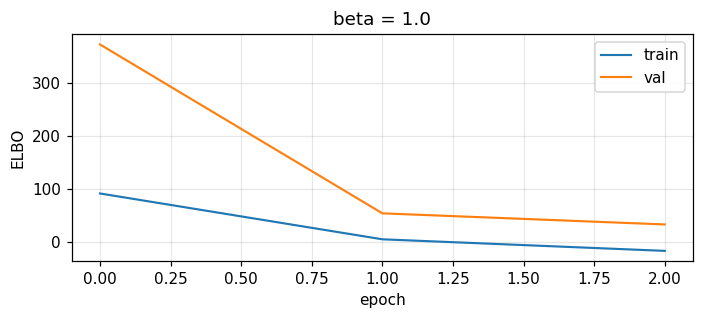

[15:32:37] smoke test done in 8.4s
smoke test OK — scored 1000 rows


In [20]:
# Smoke test: one β, three epochs, 50k picks. Confirms the training path
# works before I commit hours to the full sweep. The throwaway model is
# dropped afterwards.
SMOKE = True   # set False to skip once the training path is known good

if SMOKE:
    _sub = np.random.default_rng(RANDOM_STATE).choice(
        len(X_fit), size=min(50_000, len(X_fit)), replace=False)
    with stage("smoke test"):
        _m, _e = train(1.0, X_fit[_sub], X_va[:20_000], epochs=3, tag="(smoke)")
    print("smoke test OK — scored", score(_m, X_va[:1000]).shape[0], "rows")
    del _m
    curves.pop(1.0, None)

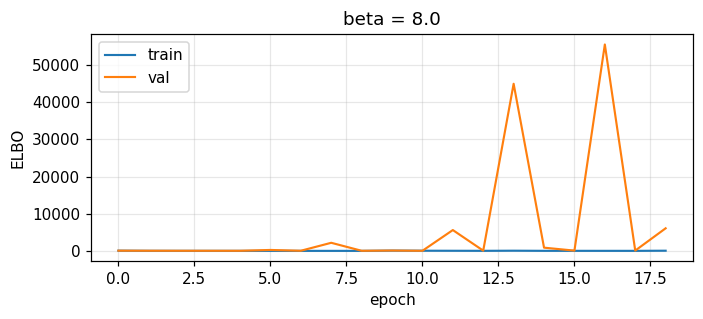

  early stop at epoch 19 (val has not improved in 10 epochs)
[15:52:38] scoring val at beta=8.0 ...
[15:52:39] scoring val at beta=8.0 done in 0.1s
beta=8.0  epochs= 19  did_mismatch AUPRC 0.087  told_locatio AUPRC 0.078  | sweep 0:20:01 elapsed, ~0:00:00 remaining

sweep complete in 0:20:01


,beta,epochs,AUPRC_did_mismatch,AUROC_did_mismatch,AUPRC_told_location_divergence,AUROC_told_location_divergence
0,0.5,25,0.0901,0.6377,0.0790,0.5777
1,1.0,25,0.0870,0.6325,0.0939,0.5766
2,2.0,25,0.0884,0.6202,0.0790,0.5715
3,4.0,22,0.0907,0.6173,0.0805,0.5761
4,8.0,19,0.0869,0.6218,0.0780,0.5747


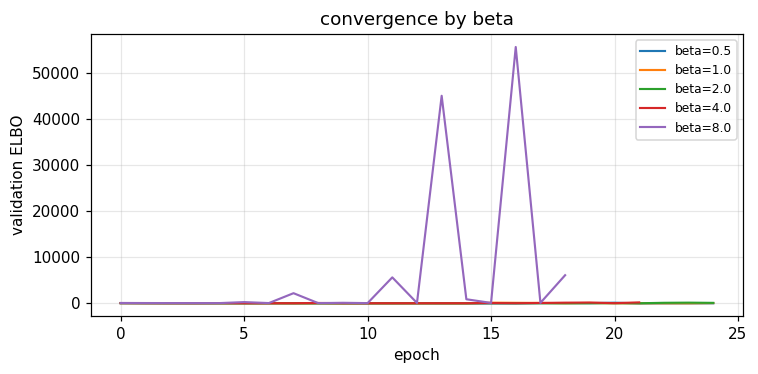

In [21]:
# The β sweep: train one VAE per β in {0.5, 1, 2, 4, 8} on the known-normal
# training picks, score validation, and record AUPRC and AUROC for each
# target. Prints elapsed and remaining time as it goes. This is the one
# expensive cell in the notebook.
from sklearn.metrics import average_precision_score, roc_auc_score

BETAS = [0.5, 1.0, 2.0, 4.0, 8.0]
sweep = []
models = {}
_t_sweep = time.perf_counter()

for k, b in enumerate(BETAS, 1):
    print(f"\n{'=' * 78}\n[{time.strftime('%H:%M:%S')}] beta {k}/{len(BETAS)} = {b}"
          f"   sweep elapsed {hms(time.perf_counter() - _t_sweep)}\n{'=' * 78}",
          flush=True)
    m, eps = train(b, X_fit, X_va, tag=f"({k}/{len(BETAS)})")
    with stage(f"scoring val at beta={b}"):
        sv = score(m, X_va)
    row = {"beta": b, "epochs": eps}
    for c in TARGETS:
        y = labels.loc[idx_val, c].to_numpy()
        row[f"AUPRC_{c}"] = average_precision_score(y, sv)
        row[f"AUROC_{c}"] = roc_auc_score(y, sv)
    sweep.append(row)
    models[b] = m
    done, left = k / len(BETAS), (len(BETAS) - k)
    el = time.perf_counter() - _t_sweep
    print(f"beta={b:<4} epochs={eps:>3}  " +
          "  ".join(f"{c[:12]} AUPRC {row[f'AUPRC_{c}']:.3f}" for c in TARGETS) +
          f"  | sweep {hms(el)} elapsed, ~{hms(el / k * left)} remaining", flush=True)

sweep = pd.DataFrame(sweep)
print(f"\nsweep complete in {hms(time.perf_counter() - _t_sweep)}", flush=True)
display(sweep.round(4))

# Validation loss curve per β — the run's own record of convergence, and the
# evidence for whether the 100-epoch cap or early stopping is what ended
# training.
fig, ax = plt.subplots(figsize=(7, 3.5))
for b, h in curves.items():
    ax.plot(h["val"], lw=1.4, label=f"beta={b}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation ELBO")
ax.set_title("convergence by beta"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

selected beta: {'did_mismatch': 4.0, 'told_location_divergence': 1.0}


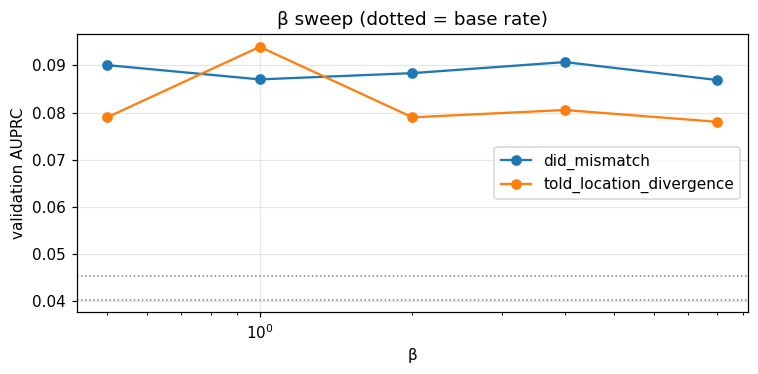

In [22]:
# Choose one β per target — the one with the best validation AUPRC — and
# plot the whole sweep. Test is not touched here.
chosen = {c: float(sweep.loc[sweep[f"AUPRC_{c}"].idxmax(), "beta"]) for c in TARGETS}
print("selected beta:", chosen)

fig, ax = plt.subplots(figsize=(7, 3.5))
for c in TARGETS:
    ax.plot(sweep["beta"], sweep[f"AUPRC_{c}"], marker="o", label=c)
    base = labels.loc[idx_val, c].mean()
    ax.axhline(base, ls=":", lw=1, color="grey")
ax.set(xscale="log", xlabel="β", ylabel="validation AUPRC",
       title="β sweep (dotted = base rate)")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Pick-grain results

AUPRC is the primary metric and is read against the base rate, not against 0.5.
Lift in the top 1% of scores is the operational number.

In [23]:
# Score TEST with each selected β and compute the headline metrics, with
# 2,000-sample bootstrap confidence intervals on both. (I added the intervals
# here because the ck_shortfall section had them and the main targets did not,
# which put more scrutiny on the secondary outcome than on the reported ones.)
N_BOOT = 2000
results = []
test_scores = {}
_rng = np.random.default_rng(RANDOM_STATE)

for c_ in TARGETS:
    m = models[chosen[c_]]
    st_full = score(m, X_te)
    test_scores[c_] = st_full   # full length, keyed to idx_test — §9 and §10 depend on this
    # Metrics use the same gated population §7 uses (D104): lines with no cobot
    # task have unknown labels, not negative ones.
    st_ = st_full[te_gate]
    y = labels.loc[idx_test, c_].to_numpy()[te_gate]
    base = y.mean()
    top = st_ >= np.quantile(st_, 0.99)

    boot_auroc, boot_auprc = [], []
    for _ in range(N_BOOT):
        i = _rng.integers(0, len(y), len(y))
        if y[i].sum():
            boot_auroc.append(roc_auc_score(y[i], st_[i]))
            boot_auprc.append(average_precision_score(y[i], st_[i]))

    results.append({
        "target": c_, "beta": chosen[c_], "base_rate": base,
        "n_pos": int(y.sum()),
        "AUPRC": average_precision_score(y, st_),
        "AUPRC_lo": np.percentile(boot_auprc, 2.5),
        "AUPRC_hi": np.percentile(boot_auprc, 97.5),
        "AUPRC_lift": average_precision_score(y, st_) / base,
        "AUROC": roc_auc_score(y, st_),
        "AUROC_lo": np.percentile(boot_auroc, 2.5),
        "AUROC_hi": np.percentile(boot_auroc, 97.5),
        "top1pct_rate": y[top].mean(),
        "top1pct_lift": y[top].mean() / base,
    })

res = pd.DataFrame(results)
display(res.round(4))
for r in results:
    print(f"{r['target']:<26} AUROC {r['AUROC']:.4f} "
          f"[{r['AUROC_lo']:.4f}, {r['AUROC_hi']:.4f}]  "
          f"AUPRC {r['AUPRC']:.4f} [{r['AUPRC_lo']:.4f}, {r['AUPRC_hi']:.4f}]")


,target,beta,base_rate,n_pos,AUPRC,AUPRC_lo,AUPRC_hi,AUPRC_lift,AUROC,AUROC_lo,AUROC_hi,top1pct_rate,top1pct_lift
0,did_mismatch,4.0,0.0308,3943,0.1553,0.1437,0.1665,5.0355,0.6416,0.6319,0.6511,0.4136,13.4123
1,told_location_divergence,1.0,0.0341,4366,0.1035,0.0948,0.1131,3.0314,0.5905,0.5811,0.6001,0.3112,9.1133


did_mismatch               AUROC 0.6416 [0.6319, 0.6511]  AUPRC 0.1553 [0.1437, 0.1665]
told_location_divergence   AUROC 0.5905 [0.5811, 0.6001]  AUPRC 0.1035 [0.0948, 0.1131]


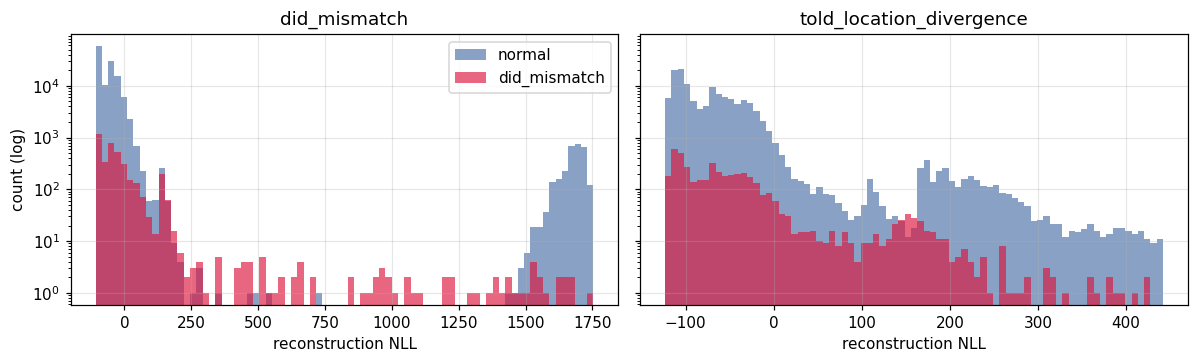

In [24]:
# Histogram of test scores, normal picks against positives, one panel per
# target, log y-axis. If the red sits to the right of the blue, the score
# separates.
fig, axes = plt.subplots(1, len(TARGETS), figsize=(11, 3.4), sharey=True)
for ax, c in zip(np.atleast_1d(axes), TARGETS):
    y = labels.loc[idx_test, c].to_numpy().astype(bool)
    s_ = test_scores[c]
    lo, hi = np.quantile(s_, [0.001, 0.999])
    bins = np.linspace(lo, hi, 80)
    ax.hist(s_[~y], bins=bins, log=True, alpha=0.65, label="normal", color="#4a6fa5")
    ax.hist(s_[y], bins=bins, log=True, alpha=0.65, label=c, color="crimson")
    ax.set(xlabel="reconstruction NLL", title=c)
np.atleast_1d(axes)[0].set_ylabel("count (log)")
np.atleast_1d(axes)[0].legend()
plt.tight_layout(); plt.show()

## 7. Supervised comparison

Same feature matrix, same temporal split, same cobot-task gate, so any
advantage is architectural rather than informational.

`HistGradientBoostingClassifier` handles NaN natively and skips the
median-impute pipeline. That is the one asymmetry and it runs in the VAE's
favor — the VAE receives explicit missingness indicators the classifier does
not.

Thresholds are chosen on validation and applied unchanged to test.

In [25]:
# Supervised comparison: a gradient-boosted classifier on the same feature
# matrix, same split and same cobot-task gate, so any gap is down to the
# architecture rather than the information. It handles NaN natively, so it
# skips the imputer. Fit on train, report on validation.
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve)

Xn = features.select_dtypes(include=[np.number])
y = labels[TARGETS[0]]

train_ok = idx_train[has_task.loc[idx_train].to_numpy()]
val_ok   = idx_val[has_task.loc[idx_val].to_numpy()]
test_ok  = idx_test[has_task.loc[idx_test].to_numpy()]

clf = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
clf.fit(Xn.loc[train_ok], y.loc[train_ok])

p_val = clf.predict_proba(Xn.loc[val_ok])[:, 1]
yv = y.loc[val_ok]
print(f"VAL   AUROC {roc_auc_score(yv, p_val):.4f} | "
      f"AUPRC {average_precision_score(yv, p_val):.4f} | base {yv.mean():.4f}")

VAL   AUROC 0.8845 | AUPRC 0.5072 | base 0.0405


In [26]:
# Leakage check on the two ordinal features. Ruled out as reverse causation —
# ticket length is fixed when the ticket is created, before any pick happens.
# Both stay in; the reduced fits here are the reported floor.
for drop, lbl in [([], "all features"),
                  (["ticket_n_lines"], "minus ticket_n_lines"),
                  (["ordinal_in_ticket", "ticket_n_lines"], "minus both ordinal")]:
    Xd = Xn.drop(columns=[c for c in drop if c in Xn.columns])
    m = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
    m.fit(Xd.loc[train_ok], y.loc[train_ok])
    pv = m.predict_proba(Xd.loc[val_ok])[:, 1]
    print(f"{lbl:<24} AUROC {roc_auc_score(yv, pv):.4f} | "
          f"AUPRC {average_precision_score(yv, pv):.4f}")

all features             AUROC 0.8845 | AUPRC 0.5072
minus ticket_n_lines     AUROC 0.8723 | AUPRC 0.4794
minus both ordinal       AUROC 0.8368 | AUPRC 0.4001


In [27]:
# Permutation importance for the classifier: shuffle one feature at a time on
# 50k validation rows and see how much AUROC drops. Top 12.
from sklearn.inspection import permutation_importance

r = permutation_importance(clf, Xn.loc[val_ok].iloc[:50000], yv.iloc[:50000],
                           n_repeats=3, random_state=RANDOM_STATE, scoring="roc_auc")
display(pd.Series(r.importances_mean, index=Xn.columns)
          .sort_values(ascending=False).head(12).round(4)
          .rename("permutation importance").to_frame())

,permutation importance
ordinal_in_ticket,0.1306
hrs_since_slot_event,0.0480
ticket_n_lines,0.0363
reserved_units_at_pick,0.0292
secs_since_worker_prev_pick,0.0272
pickzone,0.0271
forecastrank,0.0232
virtual_before,0.0164
cobot_robot_tasks_prev_15min,0.0122
aisle,0.0093


In [28]:
# Pick the operating thresholds on VALIDATION, never on test: for each recall
# target, the threshold that reaches it, with the precision and flag rate it
# implies. Named sup_thresholds because `chosen` is already the β-per-target
# dict from §5. Test base rate is 0.0308 against 0.0405 on validation, so test
# precision is if anything penalised by the sparser positive class — the
# opposite of what D136 claimed (D147).
prec, rec, thr = precision_recall_curve(yv, p_val)
sup_thresholds = {}
for target in [0.5, 0.3, 0.2, 0.1]:
    i = np.nonzero(rec >= target)[0][-1]
    t = float(thr[min(i, len(thr) - 1)])
    sup_thresholds[target] = t
    print(f"val recall {rec[i]:.0%} -> precision {prec[i]:.1%} | "
          f"flags {(p_val >= t).mean():.1%} | threshold {t:.3f}")

val recall 50% -> precision 45.8% | flags 4.4% | threshold 0.237
val recall 30% -> precision 81.3% | flags 1.5% | threshold 0.726
val recall 20% -> precision 91.6% | flags 0.9% | threshold 0.930
val recall 10% -> precision 96.7% | flags 0.4% | threshold 0.976


In [29]:
# TEST is scored once, here, with the thresholds carried over unchanged from
# validation. Nothing — no feature, hyperparameter or threshold — may change
# after this cell. Saves the threshold table.
p_test = clf.predict_proba(Xn.loc[test_ok])[:, 1]
yt = y.loc[test_ok]
print(f"TEST  AUROC {roc_auc_score(yt, p_test):.4f} | "
      f"AUPRC {average_precision_score(yt, p_test):.4f} | base {yt.mean():.4f}")
print(f"      n = {len(yt):,}, positives = {yt.sum():,}\n")

rows = []
for target, t in sup_thresholds.items():
    f = p_test >= t
    rows.append(dict(val_target=f"{target:.0%}", threshold=round(t, 3),
                     test_precision=yt[f].mean(), test_recall=yt[f].sum() / yt.sum(),
                     flag_rate=f.mean()))
sup_res = pd.DataFrame(rows)
display(sup_res.style.format({"test_precision": "{:.1%}",
                              "test_recall": "{:.1%}", "flag_rate": "{:.1%}"}))
sup_res.to_csv(OUT_DIR / "pick_models_supervised_thresholds.csv", index=False)

TEST  AUROC 0.8837 | AUPRC 0.3436 | base 0.0308
      n = 127,863, positives = 3,943



,val_target,threshold,test_precision,test_recall,flag_rate
0,50%,0.237000,29.6%,53.3%,5.5%
1,30%,0.726000,37.9%,33.1%,2.7%
2,20%,0.930000,45.7%,23.0%,1.6%
3,10%,0.976000,75.3%,11.3%,0.5%


In [30]:
# Bootstrap CI on the supervised test AUROC, which H1 commits to reporting.
# It also settled whether the two surviving cobot features moved the number:
# 0.8802 (the 46-column matrix, before the cobot features) falls inside the
# interval, so the 46- and 48-column matrices cannot be told apart on this
# evidence. I kept the features anyway so SHAP can rank a cobot feature and H3
# can be stated over all five RQ3 categories (D161); the cost of that choice
# is the test-reuse disclosure at D160.
#
# CAVEAT (D162): this resamples individual pick lines, which assumes picks are
# independent of each other. They are not — shortages cluster within tickets
# and slots — so this interval is NARROWER than the truth. Fine for the
# 46-vs-48 comparison above, since both figures come from the same rows and
# the same clustering. Not fine for the interval quoted against H1 in chapter
# 4, which needs the cluster bootstrap further down.
rng = np.random.default_rng(RANDOM_STATE)
yt_a = yt.to_numpy()
boot_auc, boot_ap = [], []
for _ in range(2000):
    i = rng.integers(0, len(yt_a), len(yt_a))
    if yt_a[i].sum() == 0:
        continue
    boot_auc.append(roc_auc_score(yt_a[i], p_test[i]))
    boot_ap.append(average_precision_score(yt_a[i], p_test[i]))
lo, hi = np.percentile(boot_auc, [2.5, 97.5])
alo, ahi = np.percentile(boot_ap, [2.5, 97.5])
print(f"TEST AUROC {roc_auc_score(yt, p_test):.4f} "
      f"[{lo:.4f}, {hi:.4f}]")
print(f"TEST AUPRC {average_precision_score(yt, p_test):.4f} "
      f"[{alo:.4f}, {ahi:.4f}]")
# 0.8802 is the pre-cobot 46-column figure; every AUROC I quote carries the
# matrix it came from (D148).
print(f"\n0.8802 (46-col matrix) inside the interval: {lo <= 0.8802 <= hi}")
print(f"H1 threshold 0.80 cleared:   {lo >= 0.80}")

TEST AUROC 0.8837 [0.8781, 0.8889]
TEST AUPRC 0.3436 [0.3277, 0.3593]

0.8802 (46-col matrix) inside the interval: True
H1 threshold 0.80 cleared:   True


In [31]:
# Confound check on has_prior_audit (D90, D98). Audit coverage climbs through
# December, so a difference either side of the flag could be calendar position
# rather than audit history. Coverage is thin and concentrated: 22,620
# slot-items have any audit event, 78% first audited in the last two weeks of
# the window, against 47 in the preceding nine months. So days_since_last_audit
# is non-null almost only for late-December picks, and its range reflects one
# two-week window rather than a spread of audit intervals. The table below
# shows the flag does not predict the outcome; it does not show the continuous
# feature spans a usable range.
ha = features["has_prior_audit"].astype(bool)
print(labels.groupby(ha, observed=True)["did_mismatch"]
      .agg(["mean", "sum", "count"]).round(4))

                   mean    sum   count
has_prior_audit                       
False            0.0465  27948  600843
True             0.0318   1901   59845


In [32]:
# SHAP attribution for the classifier — which features drive its predictions.
# Run on a 50k sample of test: TreeExplainer over the full partition takes
# minutes and the ranking is stable well below that. Top 15 by mean |SHAP|.
import shap

expl = shap.TreeExplainer(clf)
shap_idx = np.random.default_rng(RANDOM_STATE).choice(
    len(test_ok), size=min(50_000, len(test_ok)), replace=False)
X_shap = Xn.loc[test_ok].iloc[shap_idx]

t = time.perf_counter()
sv_shap = expl.shap_values(X_shap)
print(f"{len(X_shap):,} rows in {time.perf_counter() - t:.0f}s")

imp = (pd.Series(np.abs(sv_shap).mean(axis=0), index=Xn.columns)
         .sort_values(ascending=False))
display(imp.head(15).round(4).rename("mean |SHAP|").to_frame())

50,000 rows in 82s


,mean |SHAP|
ordinal_in_ticket,0.6911
ticket_n_lines,0.4187
hrs_since_slot_event,0.3726
secs_since_worker_prev_pick,0.3231
virtual_before,0.3064
pickzone,0.2786
forecastrank,0.2470
reserved_units_at_pick,0.2452
cobot_robot_tasks_prev_15min,0.2010
aisle,0.1295


## 8. Window rollup

Four statistics, all computed; the primary is selected on validation AUPRC and
the rest stay as a sensitivity table. Both thresholds are fitted on validation
only.

Base rates come from training only. Deriving them from the split being
labeled lets test set its own bar.

The `__n_picks__` row is a permanent confound check. An earlier proportional
window rule made `-n_picks` alone score AUROC 0.963. If that row moves away
from 0.5, the labels are broken, not the model.

In [33]:
# Window rollup. Base rates come from TRAINING only — if each split set its
# own base rate, test would be setting its own bar. For each target and split:
# roll the pick scores up into 15-minute windows, label the windows, and score
# every rollup statistic. Warn when a split has fewer than 30 positive
# windows, because AUPRC is unstable below that.
BASE_RATES = {c: float(labels.loc[idx_train, c].mean()) for c in TARGETS}
print("training base rates:", {k: round(v, 4) for k, v in BASE_RATES.items()})

val_scores = {c: score(models[chosen[c]], X_va) for c in TARGETS}

win_rows = []
for c in TARGETS:
    thr = float(np.quantile(val_scores[c], 0.99))
    for split, ix, sc_ in [("val", idx_val, val_scores[c]),
                           ("test", idx_test, test_scores[c])]:
        s_ser = pd.Series(sc_, index=ix)
        ts = spine.loc[ix, "tspicked"]
        wsc = W.rollup(s_ser, ts, pick_threshold=thr).set_index("window_start")
        wl = W.rollup_labels(labels.loc[ix, [c]], ts,
                             base_rates=BASE_RATES).set_index("window_start")
        j = wsc.join(wl[[c]], how="inner").dropna(subset=[c])
        n_pos = int(j[c].sum())
        if n_pos < 30:
            print(f"  !! {c} / {split}: only {n_pos} positive windows — "
                  f"AUPRC is unstable below ~30")
        for stat in W.STATISTICS:
            win_rows.append({
                "target": c, "split": split, "statistic": stat,
                "windows": len(j), "n_pos": n_pos, "window_rate": j[c].mean(),
                "AUPRC": average_precision_score(j[c], j[stat]),
                "AUROC": roc_auc_score(j[c], j[stat]),
            })
        # Permanent confound check: score the windows by pick count alone. Near 0.5
        # means window size is neutral; if it drifts away, the labels are broken, not
        # the model.
        win_rows.append({
            "target": c, "split": split, "statistic": "__n_picks__",
            "windows": len(j), "n_pos": n_pos, "window_rate": j[c].mean(),
            "AUPRC": average_precision_score(j[c], j["n_picks"]),
            "AUROC": roc_auc_score(j[c], j["n_picks"]),
        })

win = pd.DataFrame(win_rows)
display(win[win.split == "val"].round(4))

training base rates: {'did_mismatch': 0.0412, 'told_location_divergence': 0.0503}
  !! did_mismatch / test: only 16 positive windows — AUPRC is unstable below ~30
  !! told_location_divergence / test: only 15 positive windows — AUPRC is unstable below ~30


,target,split,statistic,windows,n_pos,window_rate,AUPRC,AUROC
0,did_mismatch,val,max,1092,91,0.0833,0.0960,0.4965
1,did_mismatch,val,mean,1092,91,0.0833,0.1189,0.5867
2,did_mismatch,val,topk_mean,1092,91,0.0833,0.0919,0.5070
3,did_mismatch,val,count_over,1092,91,0.0833,0.0738,0.4541
4,did_mismatch,val,__n_picks__,1092,91,0.0833,0.0503,0.2216
10,told_location_divergence,val,max,1092,86,0.0788,0.1006,0.5112
11,told_location_divergence,val,mean,1092,86,0.0788,0.1125,0.4957
12,told_location_divergence,val,topk_mean,1092,86,0.0788,0.0977,0.5074
13,told_location_divergence,val,count_over,1092,86,0.0788,0.0711,0.4533
14,told_location_divergence,val,__n_picks__,1092,86,0.0788,0.0628,0.4150


In [34]:
# Pick the rollup statistic on validation (best AUPRC per target), report that
# one on test, then show the full sensitivity table of every statistic on
# test.
best_stat = (win[win.split == "val"]
             .sort_values("AUPRC", ascending=False)
             .groupby("target").first()["statistic"].to_dict())
print("selected rollup statistic:", best_stat)

final = win[[r.split == "test" and r.statistic == best_stat[r.target]
             for r in win.itertuples()]]
display(final.round(4))
print("\nsensitivity — all statistics on test:")
display(win[win.split == "test"].pivot(index="statistic", columns="target",
                                       values="AUPRC").round(4))

selected rollup statistic: {'did_mismatch': 'mean', 'told_location_divergence': 'mean'}


,target,split,statistic,windows,n_pos,window_rate,AUPRC,AUROC
6,did_mismatch,test,mean,1155,16,0.0139,0.1892,0.8404
16,told_location_divergence,test,mean,1155,15,0.0130,0.1112,0.6147



sensitivity — all statistics on test:


target,did_mismatch,told_location_divergence
statistic,,
__n_picks__,0.0080,0.0096
count_over,0.0256,0.0137
max,0.0193,0.0299
mean,0.1892,0.1112
topk_mean,0.0189,0.0249


## 9. Attribution

Pick-grain scoring gives per-window attribution: a flagged window names the
picks that drove it, and per-feature reconstruction error names which features
made each pick strange.

This is attribution for the VAE. Where the VAE is at chance, the per-feature
ranking explains a score that does not discriminate and must not be read as a
mechanism. Permutation importance and SHAP in §7 are the equivalents attached
to a model that separates.

In [35]:
# Attribution, part 1: the three highest-scoring test windows and the five
# picks that drove each one, with their scores and labels.
c = TARGETS[0]
s_ser = pd.Series(test_scores[c], index=idx_test)
ts = spine.loc[idx_test, "tspicked"]
wsc = W.rollup(s_ser, ts, pick_threshold=float(np.quantile(test_scores[c], 0.99)))
stat = best_stat[c]
hot = wsc.nlargest(3, stat)

for _, w in hot.iterrows():
    d = W.drivers(s_ser, ts, w["window_start"], top=5)
    print(f"\nwindow {w['window_start']:%Y-%m-%d %H:%M}  "
          f"{stat}={w[stat]:.1f}  n_picks={int(w['n_picks'])}")
    show = spine.loc[d["_row"], ["tspicked", "slotid", "quantity", "quantitypicked"]]
    show["score"] = d["score"].to_numpy()
    show[c] = labels.loc[d["_row"], c].to_numpy()
    display(show)


window 2025-12-27 17:15  mean=1731.0  n_picks=1


,tspicked,slotid,quantity,quantitypicked,score,did_mismatch
573051,2025-12-27 17:25:27.900,213294,1,1,1730.977661,0



window 2025-12-27 17:20  mean=1731.0  n_picks=1


,tspicked,slotid,quantity,quantitypicked,score,did_mismatch
573051,2025-12-27 17:25:27.900,213294,1,1,1730.977661,0



window 2025-12-27 16:00  mean=1713.6  n_picks=3


,tspicked,slotid,quantity,quantitypicked,score,did_mismatch
656434,2025-12-27 16:11:25.827,265345,11,11,1729.192627,0
656436,2025-12-27 16:14:10.460,432412,1,1,1723.124878,0
656435,2025-12-27 16:12:56.467,326221,1,1,1688.493652,0


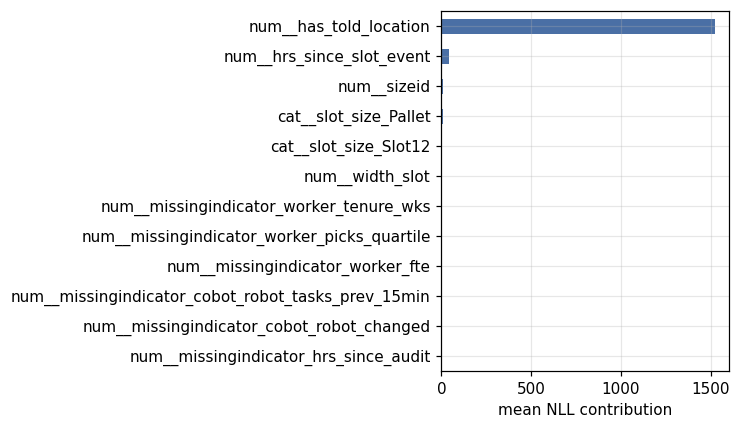

In [36]:
# Attribution, part 2: for the 2,000 strangest test picks, which features did
# the VAE reconstruct worst? Mean per-feature NLL, top 12, as a bar chart.
m = models[chosen[TARGETS[0]]]
top_idx = np.argsort(test_scores[TARGETS[0]])[-2000:]
with torch.no_grad():
    xb = torch.from_numpy(X_te[top_idx]).to(device)
    xm, xlv, _, _ = m(xb)
    per_dim = (0.5 * (xlv + (xb - xm) ** 2 / xlv.exp())).mean(0).cpu().numpy()

names = list(pre.get_feature_names_out())
attr = (pd.Series(per_dim, index=names).nlargest(12)
          .rename("mean per-feature NLL, top 2000 picks"))
fig, ax = plt.subplots(figsize=(7, 4))
attr[::-1].plot.barh(ax=ax, color="#4a6fa5")
ax.set(xlabel="mean NLL contribution")
plt.tight_layout(); plt.show()

In [37]:
# Do the two attribution name spaces describe the same features? SHAP in §7
# uses the raw column names (Xn.columns); the VAE attribution above uses the
# preprocessor's output names, which carry the imputation indicators and the
# one-hot expansions. Any side-by-side ranking in chapter 4 depends on these
# lining up.
sup_names = list(Xn.columns)
vae_names = list(pre.get_feature_names_out())
print(f"supervised (Xn):        {len(sup_names)} columns")
print(f"VAE (preprocessed):     {len(vae_names)} columns\n")

s_sup, s_vae = set(sup_names), set(vae_names)
print(f"in both:                {len(s_sup & s_vae)}")
print(f"supervised only:        {len(s_sup - s_vae)}")
print(f"VAE only:               {len(s_vae - s_sup)}\n")

# List the names, not just the counts — a count says they differ, not how.
for label, missing in [("supervised only", sorted(s_sup - s_vae)),
                       ("VAE only", sorted(s_vae - s_sup))]:
    if missing:
        print(f"{label} ({len(missing)}):")
        for nm in missing[:20]:
            print(f"    {nm}")
        if len(missing) > 20:
            print(f"    ... and {len(missing) - 20} more")
        print()

# Strip the num__/cat__ prefixes off the VAE-only names and check whether the
# stem exists in Xn, to separate transformer-added columns (indicators,
# one-hot) from genuine mismatches.
extra = sorted(s_vae - s_sup)
if extra:
    import re
    stems = pd.Series([re.sub(r"^(num__|cat__|remainder__)", "", n)
                       for n in extra])
    print("VAE-only names with the transformer prefix stripped, "
          "and whether the stem exists in Xn:")
    print(stems.map(lambda s: s in s_sup).value_counts().to_string())

supervised (Xn):        43 columns
VAE (preprocessed):     65 columns

in both:                0
supervised only:        43
VAE only:               65

supervised only (43):
    aisle
    cobot_robot_changed
    cobot_robot_tasks_prev_15min
    days_since_last_audit
    depth
    dow
    fit_ratio
    forecastrank
    has_prior_audit
    has_told_location
    height_item
    height_slot
    hour
    hrs_since_audit
    hrs_since_slot_event
    isspecialsize
    item_density
    item_volume
    last_audit_mismatch
    length
    ... and 23 more

VAE only (65):
    cat__slot_size_Pallet
    cat__slot_size_Slot12
    cat__slot_size_Slot16
    cat__slot_size_Slot16A
    cat__slot_size_Slot19L
    cat__slot_size_Slot48
    cat__slot_size_Slot6
    cat__slot_size_Slot7
    num__aisle
    num__cobot_robot_changed
    num__cobot_robot_tasks_prev_15min
    num__days_since_last_audit
    num__depth
    num__dow
    num__fit_ratio
    num__forecastrank
    num__has_prior_audit
    num__has_told_l

## 10. Saved outputs

In [38]:
# Save the results tables (pick-grain, window rollup, β sweep) and the scored
# test partition as CSV/parquet in reports/.
res.to_csv(OUT_DIR / "pick_models_pick_grain_results.csv", index=False)
win.to_csv(OUT_DIR / "pick_models_window_rollup.csv", index=False)
sweep.to_csv(OUT_DIR / "pick_models_beta_sweep.csv", index=False)
scored = spine.loc[idx_test, ["shippingintentline_id", "pickticket_id",
                              "tspicked", "slotid", "sku"]].copy()
for c in TARGETS:
    scored[f"score_{c}"] = test_scores[c]
    scored[c] = labels.loc[idx_test, c].to_numpy()
scored.to_parquet(OUT_DIR / "pick_models_scored_test.parquet", index=False)
print("written to", OUT_DIR)
for f in sorted(OUT_DIR.glob("pick_models_*")):
    print(" ", f.name)

written to C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1\reports
  pick_models_beta_sweep-ltrem-porterb.csv
  pick_models_beta_sweep.csv
  pick_models_h2_comparison-ltrem-porterb.csv
  pick_models_h2_comparison.csv
  pick_models_iforest_test.csv
  pick_models_pick_grain_results-ltrem-porterb.csv
  pick_models_pick_grain_results.csv
  pick_models_scored_test-ltrem-porterb.parquet
  pick_models_scored_test.parquet
  pick_models_scores-ltrem-porterb.pkl
  pick_models_scores.pkl
  pick_models_supervised_thresholds.csv
  pick_models_window_rollup-ltrem-porterb.csv
  pick_models_window_rollup.csv


In [39]:
# Save the trained VAEs and the val/test scores. The sweep is the only
# expensive step; everything else rebuilds from parquet in about a minute, so
# with these on disk the rollup and attribution sections can re-run without
# torch.
import pickle

torch.save(
    {"state_dicts": {float(b): {k: v.cpu() for k, v in m.state_dict().items()}
                     for b, m in models.items()},
     "d": int(X_fit.shape[1]),
     "latent": LATENT, "hidden": HIDDEN,
     "betas": [float(b) for b in BETAS],
     "chosen": {c: float(v) for c, v in chosen.items()}},
    OUT_DIR / "pick_models.pt")

# Val and test scores for the selected models, pickled together with the split
# indexes so they can be paired back up with the labels.
val_scores = {c: score(models[chosen[c]], X_va) for c in TARGETS}
with open(OUT_DIR / "pick_models_scores.pkl", "wb") as fh:
    pickle.dump({"val": val_scores, "test": test_scores,
                 "idx_val": np.asarray(idx_val), "idx_test": np.asarray(idx_test),
                 "chosen": chosen}, fh)

print("saved:", OUT_DIR / "pick_models.pt")
print("saved:", OUT_DIR / "pick_models_scores.pkl")

saved: C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1\reports\pick_models.pt
saved: C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1\reports\pick_models_scores.pkl


## 11. `ck_shortfall` as a target

`ck_shortfall` has only ever been a gate input — it sits in `LABEL_COLS`, so
`known_normal` excludes any pick carrying one — and has never been predicted.

It is the better construct for picker error: the checker barcode-scans every
piece in the bin, so a CK fires when the ordered SKU is absent from a tote that
has already left the aisle. `did_mismatch` compares `taskqty` against `execqty`
from the robot's own record and is an inventory-record event (D128).

Underpowered. After the SKU-prefix join repair (D121) the CK attach rate is 99%,
of which 861 are `ck_shortfall` — 169 positives in test. Report as a direction
with intervals, not as a headline (D127).

In [40]:
# ck_shortfall as a target, supervised. Same features, same chronological
# split, same cobot-task gate as §7 — only the target changes, so the
# comparison with the did_mismatch result is like-for-like.
SUP_TARGET_CK = "ck_shortfall"
y_ck = labels[SUP_TARGET_CK]

clf_ck = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
clf_ck.fit(Xn.loc[train_ok], y_ck.loc[train_ok])

p_val_ck = clf_ck.predict_proba(Xn.loc[val_ok])[:, 1]
yv_ck = y_ck.loc[val_ok]
print(f"VAL   AUROC {roc_auc_score(yv_ck, p_val_ck):.4f} | "
      f"AUPRC {average_precision_score(yv_ck, p_val_ck):.4f} | "
      f"base {yv_ck.mean():.4f}")

# Thresholds on VALIDATION only, same recall targets as §7.
prec_ck, rec_ck, thr_ck = precision_recall_curve(yv_ck, p_val_ck)
sup_thresholds_ck = {}
for target in [0.5, 0.3, 0.2, 0.1]:
    i = np.nonzero(rec_ck >= target)[0][-1]
    t = float(thr_ck[min(i, len(thr_ck) - 1)])
    sup_thresholds_ck[target] = t
    print(f"val recall {rec_ck[i]:.0%} -> precision {prec_ck[i]:.1%} | "
          f"flags {(p_val_ck >= t).mean():.1%} | threshold {t:.3f}")

# TEST, scored once, thresholds carried over unchanged from validation.
p_test_ck = clf_ck.predict_proba(Xn.loc[test_ok])[:, 1]
yt_ck = y_ck.loc[test_ok]
print(f"\nTEST  AUROC {roc_auc_score(yt_ck, p_test_ck):.4f} | "
      f"AUPRC {average_precision_score(yt_ck, p_test_ck):.4f} | "
      f"base {yt_ck.mean():.4f}")
print(f"      n = {len(yt_ck):,}, positives = {yt_ck.sum():,}\n")

rows_ck = []
for target, t in sup_thresholds_ck.items():
    f = p_test_ck >= t
    rows_ck.append(dict(val_target=f"{target:.0%}", threshold=round(t, 3),
                        flagged=f.mean(),
                        test_precision=yt_ck[f].mean(),
                        test_recall=yt_ck[f].sum() / yt_ck.sum(),
                        lift=yt_ck[f].mean() / yt_ck.mean()))
display(pd.DataFrame(rows_ck).round(4))

VAL   AUROC 0.5937 | AUPRC 0.0230 | base 0.0011
val recall 62% -> precision 0.1% | flags 49.9% | threshold 0.001
val recall 31% -> precision 2.2% | flags 1.5% | threshold 0.001
val recall 20% -> precision 4.0% | flags 0.5% | threshold 0.004
val recall 10% -> precision 5.3% | flags 0.2% | threshold 0.351

TEST  AUROC 0.5863 | AUPRC 0.0271 | base 0.0012
      n = 127,863, positives = 150



,val_target,threshold,flagged,test_precision,test_recall,lift
0,50%,0.001,0.5307,0.0014,0.6133,1.1558
1,30%,0.001,0.0160,0.0161,0.2200,13.7487
2,20%,0.004,0.0061,0.0362,0.1867,30.8369
3,10%,0.351,0.0028,0.0475,0.1133,40.4780


In [41]:
# β-VAE against ck_shortfall — scoring only, no refit. Declared asymmetry:
# ck_shortfall is in LABEL_COLS, so the VAE was fitted on this label's
# negatives by construction. Standard for an anomaly detector, but not
# symmetric with the classifier, which trains without that gate.
sweep_ck = []
val_sc_ck = {}
for b in BETAS:
    sv = score(models[b], X_va)[va_gate]
    val_sc_ck[b] = sv
    sweep_ck.append({"beta": b,
                     "AUROC_val": roc_auc_score(yv_ck, sv),
                     "AUPRC_val": average_precision_score(yv_ck, sv)})
sweep_ck = pd.DataFrame(sweep_ck)
display(sweep_ck.round(4))

# At ~0.1% prevalence the AUPRC spread across βs is within sampling noise, so
# this is a registered tie-break rather than a real selection. Record which
# criterion chose the value and whether AUROC would have chosen differently.
beta_ck = float(sweep_ck.loc[sweep_ck["AUPRC_val"].idxmax(), "beta"])
print("beta by val AUPRC (tie-break):", beta_ck,
      "| AUROC would choose:",
      float(sweep_ck.loc[sweep_ck["AUROC_val"].idxmax(), "beta"]))

,beta,AUROC_val,AUPRC_val
0,0.5,0.6885,0.0025
1,1.0,0.6739,0.0022
2,2.0,0.6634,0.0022
3,4.0,0.6446,0.0018
4,8.0,0.6449,0.0019


beta by val AUPRC (tie-break): 0.5 | AUROC would choose: 0.5


In [42]:
# TEST scored once for ck_shortfall, with the three checks that decide whether
# the number is quotable: a bootstrap CI; whether the score just tracks the
# calendar (Spearman against pick time); and whether it holds up inside and
# outside the holiday week (D90).
from scipy.stats import spearmanr

st_ck = score(models[beta_ck], X_te)[te_gate]
yt_arr = yt_ck.to_numpy()
base_ck = yt_arr.mean()
top_ck = st_ck >= np.quantile(st_ck, 0.99)

print(f"beta-VAE TEST AUROC {roc_auc_score(yt_arr, st_ck):.4f} | "
      f"AUPRC {average_precision_score(yt_arr, st_ck):.4f} | base {base_ck:.5f} | "
      f"n_pos {int(yt_arr.sum())}")
print(f"         AUPRC lift {average_precision_score(yt_arr, st_ck)/base_ck:.2f}x | "
      f"top-1% lift {yt_arr[top_ck].mean()/base_ck:.2f}x")

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(2000):
    i = rng.integers(0, len(yt_arr), len(yt_arr))
    if yt_arr[i].sum():
        boot.append(roc_auc_score(yt_arr[i], st_ck[i]))
print(f"         AUROC CI [{np.percentile(boot, 2.5):.4f}, "
      f"{np.percentile(boot, 97.5):.4f}]")

te_idx = idx_test[te_gate]
cal = spine.loc[te_idx, "tspicked"].astype("int64").to_numpy()
print(f"         spearman(recon, calendar) {spearmanr(st_ck, cal).statistic:+.3f}")

hol = spine.loc[te_idx, "tspicked"].dt.day.between(23, 28).to_numpy()
for nm, m in [("holiday", hol), ("non-holiday", ~hol)]:
    if yt_arr[m].sum():
        print(f"  {nm:12s} AUROC {roc_auc_score(yt_arr[m], st_ck[m]):.4f} | "
              f"n {m.sum():,} | n_pos {int(yt_arr[m].sum())} | "
              f"base {yt_arr[m].mean():.5f}")

beta-VAE TEST AUROC 0.6509 | AUPRC 0.0026 | base 0.00117 | n_pos 150
         AUPRC lift 2.24x | top-1% lift 2.67x
         AUROC CI [0.6023, 0.6981]
         spearman(recon, calendar) +0.186
  holiday      AUROC 0.6505 | n 39,215 | n_pos 39 | base 0.00099
  non-holiday  AUROC 0.6504 | n 88,648 | n_pos 111 | base 0.00125


In [43]:
# Isolation Forest as the second unsupervised family (D132). Two variants:
# fitted on ALL training picks (fully unsupervised) and on known-normal only
# (the same regime as the VAE). Both scored on validation.
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score
import time

t = time.perf_counter()
iso = IsolationForest(n_estimators=300, contamination="auto",
                      random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_tr)
s_val = -iso.score_samples(X_va)
print(f"fit+score in {time.perf_counter()-t:.1f}s")

for c in TARGETS:
    yv_ = labels.loc[idx_val, c]
    print(f"{c:<26} AUROC {roc_auc_score(yv_, s_val):.4f} | "
          f"AUPRC {average_precision_score(yv_, s_val):.4f} | base {yv_.mean():.4f}")

iso_n = IsolationForest(n_estimators=300, contamination="auto",
                        random_state=RANDOM_STATE, n_jobs=-1).fit(X_fit)
s_val_n = -iso_n.score_samples(X_va)
for c in TARGETS:
    yv_ = labels.loc[idx_val, c]
    print(f"[known-normal] {c:<22} AUROC {roc_auc_score(yv_, s_val_n):.4f} | "
          f"AUPRC {average_precision_score(yv_, s_val_n):.4f}")

fit+score in 5.1s
did_mismatch               AUROC 0.5334 | AUPRC 0.0407 | base 0.0403
told_location_divergence   AUROC 0.5121 | AUPRC 0.0448 | base 0.0453
[known-normal] did_mismatch           AUROC 0.5335 | AUPRC 0.0411
[known-normal] told_location_divergence AUROC 0.5117 | AUPRC 0.0451


In [44]:
# Cluster bootstrap for the H1 interval (closes D162). Instead of resampling
# individual picks, resample whole tickets (or whole slots) so the correlation
# inside a cluster is respected. Run both candidate units and quote the wider
# interval.
pick_ci = (lo, hi)   # pick-level CI from §7 — saved before anything else reuses lo/hi

def cluster_boot(y, p, groups, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    codes, uniq = pd.factorize(groups)
    members = (pd.Series(np.arange(len(y))).groupby(codes)
                 .apply(np.asarray).to_numpy())
    G = len(uniq); auc, ap = [], []
    for _ in range(n_boot):
        i = np.concatenate(members[rng.integers(0, G, G)])
        if y[i].sum():
            auc.append(roc_auc_score(y[i], p[i]))
            ap.append(average_precision_score(y[i], p[i]))
    return np.percentile(auc, [2.5, 97.5]), np.percentile(ap, [2.5, 97.5])

print(f"pick-level      AUROC [{pick_ci[0]:.4f}, {pick_ci[1]:.4f}]")
for unit in ["pickticket_id", "slotid"]:
    g = spine.loc[yt.index, unit].astype(str).to_numpy()
    (clo, chi), (alo, ahi) = cluster_boot(yt_a, p_test, g)
    print(f"{unit:15s} clusters {len(np.unique(g)):>7,}  "
          f"AUROC [{clo:.4f}, {chi:.4f}]  AUPRC [{alo:.4f}, {ahi:.4f}]  "
          f"H1 cleared: {clo >= 0.80}")

pick-level      AUROC [0.8781, 0.8889]
pickticket_id   clusters   8,225  AUROC [0.8766, 0.8903]  AUPRC [0.3259, 0.3608]  H1 cleared: True
slotid          clusters  19,743  AUROC [0.8766, 0.8905]  AUPRC [0.3222, 0.3652]  H1 cleared: True


In [45]:
# Same cluster bootstrap for the β-VAE, so the H2 comparison in §4.7.2 quotes
# matching intervals on both sides. The assert checks both models were scored
# on exactly the same test rows.
_vae_idx = idx_test[te_gate]
assert _vae_idx.equals(yt.index), "supervised and β-VAE test populations differ"

y_vae = labels.loc[_vae_idx, "did_mismatch"].to_numpy()
s_vae = test_scores["did_mismatch"][te_gate]
print(f"β-VAE test AUROC {roc_auc_score(y_vae, s_vae):.4f}  (expect 0.6416)")

for unit in ["pickticket_id", "slotid"]:
    g = spine.loc[_vae_idx, unit].astype(str).to_numpy()
    (clo, chi), (alo, ahi) = cluster_boot(y_vae, s_vae, g)
    print(f"{unit:15s} AUROC [{clo:.4f}, {chi:.4f}]  AUPRC [{alo:.4f}, {ahi:.4f}]")

β-VAE test AUROC 0.6416  (expect 0.6416)
pickticket_id   AUROC [0.6312, 0.6523]  AUPRC [0.1427, 0.1678]
slotid          AUROC [0.6278, 0.6547]  AUPRC [0.1399, 0.1716]


## 12. Score combination and matched-definition comparison

Validation only, except the final cell: the two forests are scored on test
there because H2 asks for a test AUROC from every model and nothing about
either forest was selected on validation. No threshold, feature or
hyperparameter changes after §7.

Three results. Rank-averaging the supervised and unsupervised scores ranks below
the supervised score alone, so no combination is reported. Refitting the
supervised model on the same disqualifying set the VAE was fitted against
removes the objection that the two answered different questions, and the gap is
unchanged. Scoring both against every label shows the reconstruction score is
flat across targets and base rates while the supervised score tracks its target.

The per-label table is the reported comparison. Set-based exclusive-flag lifts
were tried and discarded: their denominators shift between groups, which makes a
high-prevalence outcome look like a strength of whichever score is being sliced.

In [46]:
# §12, part 1: does combining the VAE and classifier scores beat the
# classifier alone? Rank-average the two on validation and compare AUROC.
from sklearn.metrics import roc_auc_score

# VAE scores cover all of idx_val; the classifier only scored val_ok (the
# gated rows), so I restrict the VAE score to the same rows before pairing
# them (D104).
C_SUP = TARGETS[0]
sv_va  = pd.Series(score(models[chosen[C_SUP]], X_va), index=idx_val).loc[val_ok]
pl_va  = pd.Series(clf.predict_proba(Xn.loc[val_ok])[:, 1], index=val_ok)
iso_va = pd.Series(s_val, index=idx_val).loc[val_ok]
y_va   = labels.loc[val_ok, C_SUP]

for nm, s in [("VAE", sv_va), ("iForest", iso_va), ("supervised", pl_va)]:
    print(f"{nm:<12} AUROC {roc_auc_score(y_va, s):.4f}")

rank_avg = pl_va.rank(pct=True) + sv_va.rank(pct=True)
print(f"\nspearman VAE/supervised {pl_va.corr(sv_va, method='spearman'):+.3f}")
print(f"rank-average            {roc_auc_score(y_va, rank_avg):.4f} vs "
      f"supervised {roc_auc_score(y_va, pl_va):.4f}")

VAE          AUROC 0.6219
iForest      AUROC 0.5371
supervised   AUROC 0.8845

spearman VAE/supervised -0.000
rank-average            0.8117 vs supervised 0.8845


In [47]:
# §12, part 2: refit the classifier on the same "any outcome" target the VAE
# was effectively fitted against (D104), so both models answer the same
# question. Compare on validation.
from sklearn.ensemble import HistGradientBoostingClassifier

y_any = (~W.known_normal(labels)).astype(int)
clf_any = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
clf_any.fit(Xn.loc[train_ok], y_any.loc[train_ok])
p_any = pd.Series(clf_any.predict_proba(Xn.loc[val_ok])[:, 1], index=val_ok)
ya = y_any.loc[val_ok]
print(f"any-outcome  sup {roc_auc_score(ya, p_any):.4f} | "
      f"vae {roc_auc_score(ya, sv_va):.4f} | base {ya.mean():.4f}")

any-outcome  sup 0.8473 | vae 0.5966 | base 0.0637


In [48]:
# §12, part 3 — the reported comparison. One metric (AUROC), both methods,
# every label with at least 30 validation positives. Shows whether the VAE
# score is flat across labels while the classifier tracks its target.
rows = []
for c in labels.columns:
    yc = labels.loc[val_ok, c]
    if yc.sum() < 30:
        print(f"skipped {c}: {int(yc.sum())} positives")
        continue
    rows.append({"label": c, "base_rate": yc.mean(), "n_pos": int(yc.sum()),
                 "AUROC_vae": roc_auc_score(yc, sv_va),
                 "AUROC_sup": roc_auc_score(yc, pl_va)})
display(pd.DataFrame(rows).round(4))

skipped exc_totefull: 1 positives


,label,base_rate,n_pos,AUROC_vae,AUROC_sup
0,ck_shortfall,0.0011,137,0.6446,0.8329
1,is_recovery_pick,0.0138,1786,0.6625,0.8698
2,did_mismatch,0.0405,5265,0.6219,0.8845
3,exc_short,0.0405,5264,0.6220,0.8845
4,told_location_divergence,0.0457,5930,0.5804,0.7713


In [49]:
# H2 needs a TEST AUROC for every model, and the two forests had only ever
# been scored on validation. Scoring them here does not breach the "test is
# touched once" rule: nothing about either forest was selected on validation —
# no threshold, no hyperparameter, contamination left at "auto" — so there is
# no selection for test to launder. Same gate and population as §6 and §7
# (D104), so all four numbers are comparable.
iso_rows = []
for nm, m in [("iForest (all training)", iso), ("iForest (known-normal)", iso_n)]:
    s_te = -m.score_samples(X_te)[te_gate]
    for c_ in TARGETS:
        yt_ = labels.loc[idx_test, c_].to_numpy()[te_gate]
        iso_rows.append({"model": nm, "target": c_,
                         "base_rate": yt_.mean(), "n_pos": int(yt_.sum()),
                         "AUROC": roc_auc_score(yt_, s_te),
                         "AUPRC": average_precision_score(yt_, s_te)})
iso_test = pd.DataFrame(iso_rows)
display(iso_test.round(4))
iso_test.to_csv(OUT_DIR / "pick_models_iforest_test.csv", index=False)

# The H2 table: one supervision regime per row, one metric, one split. Saved
# to CSV.
C0 = TARGETS[0]
h2 = pd.DataFrame([
    ("supervised",      "HistGradientBoosting", roc_auc_score(yt, p_test)),
    ("semi-supervised", "beta-VAE",
        float(res.loc[res.target == C0, "AUROC"].iloc[0])),
    ("semi-supervised", "iForest (known-normal)",
        float(iso_test.query("model.str.contains('known-normal') and target == @C0")
                      ["AUROC"].iloc[0])),
    ("unsupervised",    "iForest (all training)",
        float(iso_test.query("model.str.contains('all training') and target == @C0")
                      ["AUROC"].iloc[0])),
], columns=["regime", "model", f"test_AUROC ({C0})"])
display(h2.round(4))
h2.to_csv(OUT_DIR / "pick_models_h2_comparison.csv", index=False)


,model,target,base_rate,n_pos,AUROC,AUPRC
0,iForest (all training),did_mismatch,0.0308,3943,0.5362,0.0332
1,iForest (all training),told_location_divergence,0.0341,4366,0.5200,0.0363
2,iForest (known-normal),did_mismatch,0.0308,3943,0.5313,0.0335
3,iForest (known-normal),told_location_divergence,0.0341,4366,0.5148,0.0364


,regime,model,test_AUROC (did_mismatch)
0,supervised,HistGradientBoosting,0.8837
1,semi-supervised,beta-VAE,0.6416
2,semi-supervised,iForest (known-normal),0.5313
3,unsupervised,iForest (all training),0.5362


## 13. Rerouted lines and their residual CK rate

`told_location_divergence` marks a line the system rerouted to a second slot
after the item was reported missing at the first. The reroute exists to stop the
line becoming a CK, and it usually works — but the residual failure rate on
rerouted lines is an order of magnitude above baseline, and a substantial share
of the month's CKs originate here.

This is the strongest operational result in the notebook and it requires no
model: the trigger already exists in real time, the population is defined and
sized, and the intervention is a slot audit rather than a picker action.

The conditional question — which reroutes fail — arrived after the test look was
spent, rests on few positives, and is registered as exploratory. It belongs in
the cross-site protocol as a pre-registered secondary, not in the reported
results.

In [50]:
# Rerouted lines still become CKs at an order of magnitude above baseline, so
# the reroute mitigates rather than resolves. This is an operational finding
# and needs no model. Table: picks, CKs and CK rate by whether the line was
# rerouted, then the lift and the share of all CKs that start in a rerouted
# line.
_g = labels.groupby("told_location_divergence")["ck_shortfall"].agg(
    ["size", "sum", "mean"]).rename(
    columns={"size": "picks", "sum": "cks", "mean": "ck_rate"})
display(_g.style.format({"picks": "{:,.0f}", "cks": "{:,.0f}", "ck_rate": "{:.4%}"}))

_lift = _g.loc[1, "ck_rate"] / _g.loc[0, "ck_rate"]
_share = _g.loc[1, "cks"] / _g["cks"].sum()
print(f"rerouted lines            {_g.loc[1, 'picks']:,.0f} "
      f"({_g.loc[1, 'picks'] / _g['picks'].sum():.2%} of picks)")
print(f"CK rate when rerouted     {_g.loc[1, 'ck_rate']:.4%} vs "
      f"{_g.loc[0, 'ck_rate']:.4%} otherwise ({_lift:.1f}x)")
print(f"share of all CKs          {_share:.1%} originate in a rerouted line")

,picks,cks,ck_rate
told_location_divergence,,,
0,"629,416",573,0.0910%
1,"31,272",288,0.9210%


rerouted lines            31,272 (4.73% of picks)
CK rate when rerouted     0.9210% vs 0.0910% otherwise (10.1x)
share of all CKs          33.4% originate in a rerouted line


In [51]:
# Cross-tab is_recovery_pick against the reroute label. If a recovery pick is
# just the second attempt at the substitute slot, these are one event recorded
# twice, and the register should say so the way it does for exc_short (D99,
# D128).
_ct = pd.crosstab(labels["is_recovery_pick"], labels["told_location_divergence"])
display(_ct)
print("recovery picks that are also rerouted lines: "
      f"{_ct.loc[1, 1] / _ct.loc[1].sum():.1%}")
print("rerouted lines that are also recovery picks: "
      f"{_ct.loc[1, 1] / _ct[1].sum():.1%}")

told_location_divergence,0,1
is_recovery_pick,,
0,620080,27938
1,9336,3334


recovery picks that are also rerouted lines: 26.3%
rerouted lines that are also recovery picks: 10.7%


In [52]:
# Conditional question: among rerouted lines, which ones still fail? The
# population is defined, already flagged in real time, and small enough to act
# on. Positives are thin, so the CIs in the next cell decide what I can claim.
# Validation only.
_r = labels.index[labels["told_location_divergence"] == 1].intersection(val_ok)
_y = labels.loc[_r, "ck_shortfall"]
print(f"rerouted val lines {len(_r):,} | still CK {int(_y.sum())} "
      f"({_y.mean():.2%})")
print(f"  vae {roc_auc_score(_y, sv_va.loc[_r]):.4f} | "
      f"sup {roc_auc_score(_y, p_any.loc[_r]):.4f}")

rerouted val lines 5,930 | still CK 44 (0.74%)
  vae 0.6289 | sup 0.7354


In [53]:
# Bootstrap CIs on the conditional comparison. With this few positives the two
# intervals are expected to overlap; that says something about the sample
# size, not about the methods. Resamples with fewer than 6 positives are
# skipped.
from sklearn.utils import resample

N_BOOT_R = 2000
_pos = np.arange(len(_y))
for nm, s in [("vae", sv_va.loc[_r]), ("sup", p_any.loc[_r])]:
    b = []
    for k in range(N_BOOT_R):
        i = resample(_pos, random_state=RANDOM_STATE + k)
        if _y.iloc[i].sum() > 5:
            b.append(roc_auc_score(_y.iloc[i], s.iloc[i]))
    print(f"{nm:4s} {roc_auc_score(_y, s):.4f} "
          f"[{np.percentile(b, 2.5):.3f}, {np.percentile(b, 97.5):.3f}]  "
          f"(n_boot {len(b)})")

vae  0.6289 [0.563, 0.693]  (n_boot 2000)
sup  0.7354 [0.665, 0.799]  (n_boot 2000)


In [54]:
# CKs on lines that were never rerouted, split by whether the slot even had
# stock on hand before the pick.
_nr = labels["told_location_divergence"] == 0
print(labels[_nr].groupby(features["onhand_before"] == 0)["ck_shortfall"].agg(["size", "sum", "mean"]))

                 size  sum      mean
onhand_before                       
False          629190  572  0.000909
True              226    1  0.004425


In [55]:
# Diagnostic: is the §6 test AUROC a population artifact, a calendar
# artifact, or real? Nothing here changes a reported number — it decides which
# split's figures are quotable.
from sklearn.metrics import roc_auc_score

t_test = spine.loc[idx_test, "tspicked"].to_numpy()

for c_ in TARGETS:
    s_all = test_scores[c_]
    y_all = labels.loc[idx_test, c_].to_numpy()
    assert len(s_all) == len(y_all) == len(te_gate)

    # (A) same score, gated vs ungated population — gated matches how §7 was
    # scored.
    s_g, y_g, t_g = s_all[te_gate], y_all[te_gate], t_test[te_gate]
    print(f"\n{c_}")
    print(f"  ungated  n {len(y_all):>7,}  base {y_all.mean():.4f}  "
          f"AUROC {roc_auc_score(y_all, s_all):.4f}")
    print(f"  gated    n {len(y_g):>7,}  base {y_g.mean():.4f}  "
          f"AUROC {roc_auc_score(y_g, s_g):.4f}")

    # (B) calendar position alone as the score. Near 0.5 means time is neutral;
    # well above means any score that trends with time gets rewarded inside test.
    print(f"  time only                          AUROC "
          f"{roc_auc_score(y_g, t_g.astype('int64')):.4f}")

    # (C) AUROC inside each third of the test window. If the pooled figure is just
    # drift, these collapse.
    edges = np.quantile(t_g.astype("int64"), [0, 1/3, 2/3, 1.0])
    for k in range(3):
        m_ = (t_g.astype("int64") >= edges[k]) & (
              t_g.astype("int64") <= edges[k + 1] if k == 2
              else t_g.astype("int64") < edges[k + 1])
        if y_g[m_].sum() >= 30:
            print(f"  tercile {k+1}  n {m_.sum():>7,}  base {y_g[m_].mean():.4f}  "
                  f"AUROC {roc_auc_score(y_g[m_], s_g[m_]):.4f}")

# Same checks for the classifier, on the rows it was scored on.
if "p_test" in dir():
    y_s = yt.to_numpy() if hasattr(yt, "to_numpy") else np.asarray(yt)
    t_s = t_test[te_gate].astype("int64")
    assert len(p_test) == len(y_s) == len(t_s), (len(p_test), len(y_s), len(t_s))
    print(f"\nsupervised  pooled AUROC {roc_auc_score(y_s, p_test):.4f}")
    edges = np.quantile(t_s, [0, 1/3, 2/3, 1.0])
    for k in range(3):
        m_ = (t_s >= edges[k]) & (t_s <= edges[k+1] if k == 2 else t_s < edges[k+1])
        if y_s[m_].sum() >= 30:
            print(f"  tercile {k+1}  base {y_s[m_].mean():.4f}  "
                  f"AUROC {roc_auc_score(y_s[m_], p_test[m_]):.4f}")


did_mismatch
  ungated  n 130,791  base 0.0301  AUROC 0.6270
  gated    n 127,863  base 0.0308  AUROC 0.6416
  time only                          AUROC 0.4974
  tercile 1  n  42,621  base 0.0307  AUROC 0.6324
  tercile 2  n  42,621  base 0.0330  AUROC 0.6438
  tercile 3  n  42,621  base 0.0288  AUROC 0.6650

told_location_divergence
  ungated  n 130,791  base 0.0334  AUROC 0.5773
  gated    n 127,863  base 0.0341  AUROC 0.5905
  time only                          AUROC 0.4838
  tercile 1  n  42,621  base 0.0355  AUROC 0.5982
  tercile 2  n  42,621  base 0.0355  AUROC 0.5764
  tercile 3  n  42,621  base 0.0315  AUROC 0.6062

supervised  pooled AUROC 0.8837
  tercile 1  base 0.0307  AUROC 0.8929
  tercile 2  base 0.0330  AUROC 0.8936
  tercile 3  base 0.0288  AUROC 0.8667


In [56]:
# Daily pick volume and outcome rate across the test window, to see where the
# operation changed. If I split the period, the split has to be justified by
# the shipping cutoff, not chosen from these numbers.
_d = pd.DataFrame({
    "day": spine.loc[idx_test, "tspicked"].dt.floor("D").to_numpy(),
    "gate": te_gate,
})
for c_ in TARGETS:
    _d[c_] = labels.loc[idx_test, c_].to_numpy()

_g = _d[_d["gate"]].groupby("day").agg(
    picks=("gate", "size"),
    **{c_: (c_, "mean") for c_ in TARGETS},
)
print(_g.assign(picks=_g["picks"].map("{:,}".format)).round(4).to_string())

             picks  did_mismatch  told_location_divergence
day                                                       
2025-12-21  13,921        0.0251                    0.0350
2025-12-22  22,470        0.0356                    0.0383
2025-12-23  12,073        0.0334                    0.0378
2025-12-24  10,331        0.0341                    0.0387
2025-12-26   5,340        0.0416                    0.0373
2025-12-27  11,471        0.0303                    0.0349
2025-12-29  21,618        0.0249                    0.0259
2025-12-30  20,412        0.0258                    0.0294
2025-12-31  10,227        0.0396                    0.0395


In [57]:
# Permanent guard (D134). Lines with no pick timestamp are not picks: they
# carried a 66.4% did_mismatch rate with almost entirely imputed features, and
# they inflated test AUROC from 0.6513 to 0.8343 for the VAE and 0.8802 to
# 0.9286 for the classifier. (Those classifier figures came from the 46-column
# matrix before the cobot timing features; the current 48-column matrix reads
# 0.8837 — D148, D161. The point stands either way; the inflation is what this
# guards against.) They are dropped at the split in §3; this asserts they have
# not come back, then reprints the test AUROCs.
_t = spine.loc[idx_test, "tspicked"]
nat = _t.isna().to_numpy()
assert not nat.any(), f"{int(nat.sum()):,} timestamp-less lines back in test — see D134"
print(f"no-timestamp guard: 0 of {len(nat):,} test rows")

for c_ in TARGETS:
    y_ = labels.loc[idx_test, c_].to_numpy()[te_gate]
    s_ = test_scores[c_][te_gate]
    print(f"  VAE  {c_:<26} AUROC {roc_auc_score(y_, s_):.4f} "
          f"(n {te_gate.sum():,}, base {y_.mean():.4f})")

if "p_test" in dir():
    y_s = yt.to_numpy() if hasattr(yt, "to_numpy") else np.asarray(yt)
    print(f"  supervised{'':<24} AUROC {roc_auc_score(y_s, p_test):.4f}")

no-timestamp guard: 0 of 130,791 test rows
  VAE  did_mismatch               AUROC 0.6416 (n 127,863, base 0.0308)
  VAE  told_location_divergence   AUROC 0.5905 (n 127,863, base 0.0341)
  supervised                         AUROC 0.8837


In [58]:
# ordinal_in_ticket is the top SHAP feature at 0.6911, nearly double
# ticket_n_lines at 0.4187. Its cobot-side twin was removed at D158 for leaking
# through the difference between them. The WMS ordinal is clean in that
# specific way — it is assigned when the ticket is built, before any pick —
# but a feature that dominates this heavily right after a close relative was
# removed for leaking earns a look. First: outcome rate by decile of each
# feature.
_g = has_task.to_numpy()
_y = labels["did_mismatch"].to_numpy()[_g]
_base = _y.mean()
print(f"base rate, gated population: {_base:.2%}\n")

for _c in ["ordinal_in_ticket", "ticket_n_lines"]:
    _v = features[_c].to_numpy()[_g]
    _ok = ~pd.isna(_v)
    _d = pd.qcut(pd.Series(_v[_ok]), 10, labels=False, duplicates="drop")
    _t = (pd.DataFrame({"d": _d, "y": _y[_ok], "v": _v[_ok]}).groupby("d")
            .agg(n=("y", "size"), rate=("y", "mean"),
                 lo=("v", "min"), hi=("v", "max")))
    _t["lift"] = (_t["rate"] / _base).round(2)
    _t["rate"] = (_t["rate"] * 100).round(2)
    print(f"=== {_c}")
    print(_t.to_string())
    print(f"    max/min lift: {_t['lift'].max() / _t['lift'].min():.1f}x\n")

# The D158 question, asked of the survivor: does a pick's position predict
# the OTHER lines on its ticket? Ticket construction is fixed before any pick
# happens, so it should not. Then the rate by ordinal quartile within
# ticket-size bands, with row counts.
_pt = spine["pickticket_id"].astype(str).str.upper()
_tk = pd.DataFrame({"pt": _pt, "y": labels["did_mismatch"],
                    "o": features["ordinal_in_ticket"]})[_g]
_per = _tk.groupby("pt").agg(n_short=("y", "sum"), n_lines=("y", "size"))
_tk = _tk.merge(_per, left_on="pt", right_index=True)
_tk["others"] = ((_tk["n_short"] - _tk["y"]) /
                 (_tk["n_lines"] - 1).clip(lower=1))
_dd = pd.qcut(_tk["o"], 10, labels=False, duplicates="drop")
print("by ordinal decile: this pick's rate vs the rest of its ticket's rate")
print(_tk.assign(d=_dd).groupby("d").agg(
    own=("y", "mean"), others=("others", "mean"), n=("y", "size"))
    .round(4).to_string())

print("\nshortage rate by ordinal quartile within ticket-size bands:")
_band = pd.cut(_tk["n_lines"], [0, 2, 5, 10, 20, 1000],
               labels=["1-2", "3-5", "6-10", "11-20", "21+"])
_oq = pd.qcut(_tk["o"], 4, labels=["Q1", "Q2", "Q3", "Q4"], duplicates="drop")
_x = pd.DataFrame({"band": _band, "oq": _oq, "y": _tk["y"].to_numpy()})
print(_x.groupby(["band", "oq"], observed=True)["y"]
        .mean().unstack().round(4).to_string())
print("\nrow counts:")
print(_x.groupby(["band", "oq"], observed=True)["y"]
        .size().unstack().to_string())

base rate, gated population: 4.58%

=== ordinal_in_ticket
       n  rate    lo    hi  lift
d                               
0  84289  1.35   0.0   1.0  0.30
1  81913  2.34   2.0   3.0  0.51
2  39757  3.32   4.0   4.0  0.73
3  72234  3.47   5.0   6.0  0.76
4  70008  4.20   7.0   8.0  0.92
5  61563  5.51   9.0  10.0  1.20
6  49211  5.29  11.0  12.0  1.16
7  68110  5.48  13.0  16.0  1.20
8  55497  4.92  17.0  23.0  1.07
9  64238  4.82  24.0  83.0  1.05
    max/min lift: 4.0x

=== ticket_n_lines
       n  rate  lo  hi  lift
d                           
0  96893  4.26   1  10  0.93
1  54829  5.04  11  12  1.10
2  68063  5.14  13  14  1.12
3  46841  5.08  15  15  1.11
4  86809  5.19  16  18  1.13
5  57858  5.18  19  20  1.13
6  46910  5.18  21  23  1.13
7  66341  4.06  24  34  0.89
8  64431  3.18  35  43  0.70
9  63251  3.80  44  86  0.83
    max/min lift: 1.6x

by ordinal decile: this pick's rate vs the rest of its ticket's rate
        own  others      n
d                         
0.0  0.0